# Where noise must enter to change the model's algorithm

**Experiment (iteration 4) — demo notebook.** Isotropic random noise written into Qwen3-8B's residual stream can make the model write a *different correct algorithm* for the same coding task, for example quickselect instead of a full sort for "k-th smallest". This experiment asks **where** that noise has to enter. It writes the same random displacement, at the same per-position dose, into six sites, then checks which sites change the algorithm without breaking the program:

| Site | Positions edited | Decoder blocks |
|---|---|---|
| **S0** | task-specification tokens | 12-23 |
| S1 | read position R (last prompt token) | 12-23 |
| S2 | condition sentence | 12-23 |
| S3 | generated tokens 1-32 | 12-23 |
| S4 | task-specification tokens | 0-11 |
| S5 | task-specification tokens | 24-35 |

S1E and S2E are energy-matched variants of S1 and S2 at alpha 1. The dose alpha (1, 2 or 4) counts per-position *ban units*: a ban unit is the size of the displacement that a prompt-level ban ("Do not use …") causes at that block and position.

There are six tasks, each with a default algorithm: T03 k-th smallest (full sort), T05 two sum (hash map), T06 find duplicate (hash set), T10 connected components (union-find), T1 grid path (BFS) and T2 weighted shortest path (Dijkstra).

Each common-random-numbers (CRN) **slot** (task, template, k) gives every arm the same random direction and the same stream of sampling uniforms. So any two sites can be compared slot by slot as exact paired flips.

Each site is **priced** on a *randomisation hull*. The price **H5** is the best correct-only diversity of algorithms (rarefied Hill-1) that any mixture of the clean twin and the three doses reaches within a pass-rate cost of 0.05. The pre-registered **C1-site rule** asks whether S0 has the best H5 on at least 4 of the 6 tasks.

**What runs here.** `method.py` is an orchestrator: `uv run method.py <stage>` runs one script under `src/`. The GPU stages sampled 4,510 programs from Qwen3-8B (FP8, about 2.5 h on a 16 GB FP8-capable GPU) and cannot run in Colab. Their output, the labelled programs, is this demo's data. The notebook inlines the three CPU stages, as the original code split into cells:

| `method.py` stage | Original file(s) | In this notebook |
|---|---|---|
| `tests-cpu` | `tests/test_cpu.py`, `src/hooks.py`, `src/hull.py` | unit tests of the edit maths, the hull, the permutation null and the binomial p-value |
| `analysis` | `src/analysis.py` (STEP 11), `src/hull.py`, `src/cfg.py` | cells, hull + bootstrap, C1-site decision, failure modes, paired flips, transmission GLM, pooled model, dose curve |
| `figures` | `src/figures.py` | figures 1-5 and 7 |

**Data.** `mini_demo_data.json` holds 90 of the 180 CRN slots of the `site_grid` dataset: all 6 tasks × 5 templates, slots k = 0-2. Each slot carries all 21 of its programs (the twin plus 20 arms), 1,890 labelled programs in all. A cell therefore holds 15 programs instead of the full run's 30. The summary at the end prints the full-run numbers next to the demo's.

**Runtime.** About 5 minutes on a 2-core CPU, most of it the bootstrap of the hull prices (B = 200; the full run used 2,000).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (pinned as in the experiment's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, statsmodels, matplotlib, torch — pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'matplotlib==3.10.0')
    _pip('torch==2.9.0+cpu', '--extra-index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# --- original imports: src/cfg.py
import hashlib
import json
import math
import os
import resource
import sys
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

from loguru import logger

# --- original imports: src/hull.py
import itertools

import numpy as np

# --- original imports: src/analysis.py
import ast
import glob
import multiprocessing as mp
import time
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor

# --- original imports: src/hooks.py, tests/test_cpu.py
from typing import Callable

import torch

# --- original imports: src/figures.py
import matplotlib
import matplotlib.pyplot as plt

# --- notebook additions: readable tables, and warnings printed without file paths
import warnings

import pandas as pd
from IPython.display import display

warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-4/experiment-20/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# An older copy of mini_demo_data.json in a different format can sit at GITHUB_DATA_URL until this notebook's own data
# file is published; in that case use the local copy.
if "metadata_programs" not in data["datasets"][0]["examples"][0] and Path("mini_demo_data.json").exists():
    print("GitHub copy is in an older format, using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
examples = data["datasets"][0]["examples"]
print(f"dataset '{data['datasets'][0]['dataset']}': {len(examples)} CRN slots, "
      f"{sum(len(ex['metadata_programs']) for ex in examples)} labelled programs")

GitHub copy is in an older format, using local mini_demo_data.json
dataset 'site_grid': 90 CRN slots, 1890 labelled programs


### One CRN slot

Each example is one slot (task, template, k):

- `input` is the neutral twin prompt;
- `output` is the clean twin's `<algorithm label>|pass/fail`;
- `predict_<site>_a<alpha>` is the same field for each arm on that slot;
- `metadata_programs` holds one record per program with the fields the analysis reads: the labeller's label, the pass flag, the extracted code and its sha256, the realised displacement at R (block 35), the first-token KL, the S3 step-wise KL and the finish reason.

In [5]:
ex = examples[0]
print(ex["input"])
print("\ndefault algorithm:", ex["metadata_default"], "| clean twin:", ex["output"])
print(pd.Series({k[len("predict_"):]: v for k, v in ex.items() if k.startswith("predict_")}).to_string())

task=T03 template=W1 slot k=0 (neutral twin prompt; every arm edits this prompt's states with the slot's shared random direction):
Do not use man for this task. . .

Task: write a Python function solve(nums, k) that returns the k-th smallest value in nums. The argument nums is a list of integers with 1 <= len(nums) <= 2000, and every value lies between -10000 and 10000 inclusive; values may repeat. The argument k is an integer with 1 <= k <= len(nums), counted from 1, so k = 1 asks for the minimum and k = len(nums) for the maximum. Repeated values are counted separately: for nums = [3, 1, 3] and k = 3 the answer is 3.

Use only the Python standard library. Return only one ```python code block containing the function solve and any helpers, with no example usage and no explanation.

default algorithm: full_sort | clean twin: full_sort|pass
S0_a1       quickselect|pass
S0_a2     counting_sort|fail
S0_a4         full_sort|fail
S1_a1         full_sort|pass
S1_a2         full_sort|pass
S1_a4

## Configuration

All compute knobs of the CPU stages are set here; re-run the cells below after changing them. The comments give the original full-run values. The full run's analysis was `python analysis.py 2000 5` (2,000 bootstrap replicates on 5 worker processes, about 17 min) on all 180 slots.

The protocol constants frozen before sampling are not knobs and stay as they are in `src/hull.py`: rarefaction depth 25, cost bound 0.05, Hill targets 1.5 / 2.0, and the decision thresholds.

In [6]:
# Slots analysed: mini_demo_data.json holds k = 0, 1, 2 for every task and template (5 templates -> 5 programs per
# cell for each k). The full run used k 0-5 (N = 30 per cell; twin k 0-9, N = 50).
DEMO_K = [0, 1, 2]
# STEP 11.2 randomisation hull, point estimates: CRN draws per mixture and simplex grid step (original: 1000, 0.05)
HULL_N_DRAWS = 1000
HULL_STEP = 0.05
# STEP 11.2 template-stratified bootstrap of the hull prices: replicates, then CRN draws and grid step inside each
# replicate (original: 2000 replicates in the run (method.py default 1000), 200 draws, step 0.1)
B = 200  # demo: about 0.9 s per replicate on 2 CPU cores; the original 2000 would take about 30 min
BOOT_N_DRAWS = 200
BOOT_STEP = 0.1
# bootstrap worker processes (original: 5); the notebook runs the replicates sequentially, see STEP 11.2
WORKERS = 1
# subsamples per rarefied Hill-1 number in every cell (original: 1000)
RAREFY_N_SUB = 1000

## Shared constants and utilities (`src/cfg.py`)

These are the conventions every stage shares:

- Block *l* is decoder block *l*; its output is `hidden_states[l + 1]`.
- In the prompt, *S* is the task specification, *R* = *P* − 1 is the last prompt token and *COND* is the condition sentence.
- A CRN slot (task, template, k) fixes the random direction `u(t, w, k) = normalise(PCG64(stable_seed('PN4', t, w, k)).standard_normal(4096))` and the token uniforms.

The cell also defines the tasks with their default algorithms, the site → blocks / positions maps and the slot ranges (`N_GRID_K` = k 0-5 for the site cells, `N50_K` = k 0-9 for the twin). It also defines the JSON helpers that write `results/*.json`.

The only change is `ROOT`. A notebook has no `__file__`, so everything this demo writes (`results/`, `figures/`, `logs/`) goes under `./demo_outputs/`. The model, input-artifact and GPU constants are kept for reference; nothing below loads the model.

In [7]:
"""Shared constants, paths and utilities for 'Where noise must go to change the idea' (iteration 4).

Conventions (stated again in README.md and method_out.json):
- BLOCK l = decoder block l (0-based); its output is HF hidden_states[l + 1] (exp17 convention).
- Prompt layout (exp8/exp17): '<|im_start|>user\\n' + condition sentence + '\\n\\n' + task specification + chat tail.
  COND = [p0, p1) = the condition sentence (padding included; the chat header excluded; when the tokenizer merges the
  final '.' with the '\\n\\n' separator, that merged token is part of COND and is reported in results/positions.json).
  S = [p1, spec_end) from the first 'Task:' token to the last user-message token. R = P - 1 (last chat-tail token).
- Generated input position k (1-based) = absolute position P + k - 1 (generated token k is the INPUT there).
- CRN slot = (task, template, k): token uniforms u_stream(task, template, k) (exp17 key) and the random direction
  u(t, w, k) = normalise(PCG64(stable_seed('PN4', t, w, k)).standard_normal(4096)) are shared by EVERY arm.
"""

# (imports: see the imports cell)

ROOT = Path.cwd() / "demo_outputs"  # notebook: no __file__ (original: Path(__file__).resolve().parents[1])
INPUTS = ROOT / "inputs"
E17 = INPUTS / "exp17"
E13 = INPUTS / "exp13"
E18 = INPUTS / "exp18"
E11 = INPUTS / "exp11"
E8 = INPUTS / "exp8"
E9 = INPUTS / "exp9"
E7 = INPUTS / "exp7"
BENCH = E11 / "bench"
SUITE = E8 / "suite"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
UNITS_DIR = ROOT / "units"
DIR_DIR = ROOT / "directions"
PRED_DIR = ROOT / "predictions"
AUDIT_DIR = ROOT / "audit"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, UNITS_DIR, DIR_DIR, PRED_DIR, AUDIT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# Declared dataset dependency art_j3Rm_lr2nzR6 (read in place; never written): set ART_J3RM_DIR to the folder holding
# its full_data_out.json (default: a sibling folder named art_j3Rm_lr2nzR6).
DEP_DATASET = Path(os.environ.get("ART_J3RM_DIR", str(ROOT.parent / "art_j3Rm_lr2nzR6")))

# ------------------------------------------------------------------------------------------------ model
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
N_LAYERS = 36
D_MODEL = 4096
IM_END = 151645
ENDOFTEXT = 151643
MAX_NEW_TOKENS = 1024
TEMPERATURE = 1.0
DECODING = "T1.0_topp1.0_topk-off_max1024_thinkoff_fencestop"
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"
QUANT = "fp8_e4m3_w8a8_dynamic(per-output-channel weight scales, per-token activation scales; lm_head/embeddings/norms bf16)"
BATCH = 20  # fixed batch shape (exp17's U1b-verified shape on this GPU); never changes within or across tasks


def model_path(model_id: str = MODEL_ID, revision: str | None = MODEL_REVISION) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snaps = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots"
        if revision and (snaps / revision).exists():
            return str(snaps / revision)
    return model_id


# ------------------------------------------------------------------------------------------------ tasks
TASKS = ("T03", "T05", "T06", "T10", "T1", "T2")
PATH_TASKS = ("T1", "T2")
BENCH_TASKS = ("T03", "T05", "T06", "T10")
DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T05": "hash_map", "T06": "hash_set",
           "T10": "union_find"}
EXP8_TASK = {"T1": "t1", "T2": "t2"}
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
TASK_ORDER_DROP = ("T10", "T06", "T05")  # fallback: whole tasks dropped in this order

# ------------------------------------------------------------------------------------------------ sites
PLAN_BLOCKS = list(range(12, 24))
LOW_BLOCKS = list(range(0, 12))
HIGH_BLOCKS = list(range(24, 36))
SITES = ("S0", "S1", "S2", "S3", "S4", "S5")
SITE_BLOCKS = {"S0": PLAN_BLOCKS, "S1": PLAN_BLOCKS, "S2": PLAN_BLOCKS, "S3": PLAN_BLOCKS, "S4": LOW_BLOCKS,
               "S5": HIGH_BLOCKS, "S1E": PLAN_BLOCKS, "S2E": PLAN_BLOCKS, "TOP5": PLAN_BLOCKS, "ENG": PLAN_BLOCKS}
SITE_POS = {"S0": "S", "S1": "R", "S2": "COND", "S3": "GEN1-32", "S4": "S", "S5": "S", "S1E": "R", "S2E": "COND",
            "TOP5": "S", "ENG": "S"}
S3_STEPS = 32  # generated input positions 1-32
NORM_BLOCKS = list(range(12, N_LAYERS))  # realised displacement at R logged at blocks 12-35
ALPHAS_GRID = (1.0, 2.0, 4.0)
ALPHA_BOUNDARY = 8.0
N_GRID_K = list(range(6))      # k 0-5 x 5 templates = N 30
N50_K = list(range(10))        # k 0-9 x 5 templates = N 50
SMOKE_K0 = 100                 # smoke slots k >= 100 are never analysed
FILL_K0 = 10                   # filler twin rows (TWIN_X) use k >= 10 (descriptive only)

JUDGE_CAP_LABEL_USD = 0.40
AUDIT_CAP_USD = 0.50
CONTROL_CAP_USD = 0.05
ARTIFACT_CAP_USD = 1.00
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def container_ram_gb() -> float | None:
    for p in ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"):
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return None


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.floor(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined str) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def canonical_json(obj: Any) -> str:
    """Sorted keys, floats rounded to 6 decimals, no whitespace (byte-stable)."""
    def rnd(o: Any) -> Any:
        if isinstance(o, float):
            return round(o, 6) if math.isfinite(o) else None
        if isinstance(o, dict):
            return {str(k): rnd(v) for k, v in o.items()}
        if isinstance(o, (list, tuple)):
            return [rnd(v) for v in o]
        return o
    return json.dumps(rnd(json.loads(json.dumps(obj, default=_json_default))), sort_keys=True,
                      separators=(",", ":"))


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def wilson_ci(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def rel(p: Path | str) -> str:
    """Path relative to the artifact root (never write absolute server paths into published files)."""
    try:
        return str(Path(p).resolve().relative_to(ROOT))
    except ValueError:
        return str(p)

## The intervention: displacement-targeted edits (`src/hooks.py`)

Every arm changes block outputs with the same rule. At each hooked block *l* and position *i*, it sets the displacement from the clean twin **along the slot's random unit direction u** to exactly `target = alpha × unit[l, i]`. The components orthogonal to *u* are left as they are:

`h ← h + (target − (h − h_twin)·u) u`   (computed in fp32, cast back to bf16)

Each block re-targets the *total* displacement, so nothing compounds across blocks, and alpha = 0 is the identity on the twin.

On the GPU these functions run as forward hooks on Qwen3-8B's decoder blocks, at the site's positions (S, R or COND). The S3 edit lives in the sampler instead, because it needs the teacher-forced shadow rows. The unit test below runs `apply_edit_tensor` on synthetic tensors.

In [8]:
"""Displacement-targeted block-output edits (generalising exp17 hooks.make_edits to every site).

edit(h, l, idx, u, target, h_ref):  hs = h[:, idx].float();  coef = target - (hs - h_ref) . u;
                                    h[:, idx] = (hs + coef[..., None] * u).to(bf16)
so the displacement from the clean neutral twin ALONG u is exactly `target` at every hooked block and position
(no compounding across blocks: each block re-targets the total displacement), and components orthogonal to u are
left as they are. Computed in fp32, cast back to bf16. alpha = 0 (target 0) is the identity on the twin.

Prefill sites: S0/S4/S5/TOP5/ENG on the task-spec positions S, S1/S1E on R, S2/S2E on the condition span COND.
The S3 decode site lives in engine.sample (it needs the shadow rows of the same batch).
"""

# (imports: see the imports cell)


def make_prefill_edits(blocks: list[int], idx: torch.Tensor, u: dict[int, torch.Tensor],
                       target: dict[int, torch.Tensor], h_ref: dict[int, torch.Tensor]
                       ) -> dict[int, Callable[[torch.Tensor], torch.Tensor]]:
    """idx: LongTensor of positions; u: {l: fp32 [D] unit}; target: {l: fp32 [len(idx)]};
    h_ref: {l: fp32 [len(idx), D]} (clean twin block outputs at idx)."""
    edits = {}
    for l in blocks:
        def f(h: torch.Tensor, l: int = l) -> torch.Tensor:
            hs = h[:, idx].float()                       # [1, n, D]
            ul = u[l]
            comp = (hs - h_ref[l]) @ ul                  # [1, n]
            coef = target[l] - comp
            new = hs + coef[..., None] * ul
            h = h.clone()
            h[:, idx] = new.to(h.dtype)
            return h
        edits[l] = f
    return edits


def apply_edit_tensor(h: torch.Tensor, idx: torch.Tensor, ul: torch.Tensor, target: torch.Tensor,
                      h_ref: torch.Tensor) -> torch.Tensor:
    """Pure-tensor version of one block's edit (used by the CPU unit tests)."""
    hs = h[:, idx].float()
    coef = target - (hs - h_ref) @ ul
    out = h.clone()
    out[:, idx] = (hs + coef[..., None] * ul).to(h.dtype)
    return out

## Diversity and price: rarefied Hill numbers and the randomisation hull (`src/hull.py`)

`src/hull.py` was committed before the first decisive sample. It defines the measurement and the decision:

- **Rarefied Hill-1** of a cell is the mean of exp(Shannon entropy of the algorithm labels) over subsamples of 25 *correct* programs. 1.0 means every correct program uses the same algorithm; 2.0 is as diverse as an even split between two algorithms.
- **Randomisation hull** of a (task, site): it mixes the four settings {twin, alpha 1, alpha 2, alpha 4} with weights *w* on a simplex grid, with at most 3 non-zero weights.
  - The cost of *w* is pass_twin − Σ w_j pass_j.
  - Hill(*w*) comes from a two-stage draw under common random numbers. The first stage draws how many programs come from each setting; the second draws which of that setting's correct programs.
- **Prices**: **H5** = max Hill(*w*) with cost ≤ 0.05. **P15 / P20** = the cheapest cost that reaches Hill 1.5 / 2.0 (∞ if never reached).
- **C1-site rule**: per task, the best site is the argmax of H5 rounded to 0.01, with ties going to the lower P15.
  - CONFIRMED if S0 is best on ≥ 4 of 6 tasks (raw p = P(X ≥ count) under Bin(6, 1/6)).
  - DISCONFIRMED if one other site has H5 ≥ H5(S0) on ≥ 4 tasks.
  - PARTIAL otherwise.

The code is the original except that the rarefaction's subsample count now defaults to `RAREFY_N_SUB` from the config cell.

In [9]:
"""STEP 11.1-11.3 core (committed in #1): rarefied Hill numbers, the randomisation hull per (task, site), the prices
H5 / P15 / P20, and the frozen C1-site decision rule.

Rarefied Hill-1 at depth m (Chao et al. 2014 convention): mean over subsamples of size m drawn without replacement
from the correct programs of a cell of exp(Shannon entropy of the subsample's label composition).

Randomisation hull (Provost and Fawcett 2001 style randomisation between operating points): settings j in {twin
(alpha 0), alpha 1, alpha 2, alpha 4} of one site; mixture weights w on the simplex (grid 0.05, at most 3 non-zero);
cost(w) = pass_twin - sum_j w_j pass_j; Hill(w) by a two-stage draw: n_j ~ Multinomial(25, pi_j), pi_j proportional to
w_j pass_j, then n_j correct programs of setting j without replacement (with replacement beyond N_correct_j,
flagged); 1,000 draws under common random numbers across w. H5 = max Hill(w) s.t. cost <= 0.05;
P15 / P20 = min cost s.t. Hill(w) >= 1.5 / 2.0, else 'not reached' (inf).
"""

# (imports: see the imports cell)

DEPTH = 25
GRID_STEP = 0.05
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def hill1(counts: np.ndarray) -> np.ndarray:
    """exp(Shannon entropy) along the last axis of a count array."""
    c = np.asarray(counts, dtype=np.float64)
    n = c.sum(-1, keepdims=True)
    p = np.where(n > 0, c / np.maximum(n, 1e-12), 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.where(p > 0, p * np.log(p), 0.0).sum(-1)
    return np.exp(h)


def rarefied_hill(labels: list[str], depth: int = DEPTH, n_sub: int = RAREFY_N_SUB, seed: int = 0) -> dict[str, Any]:
    """Rarefied Hill-1; cells with fewer than `depth` correct programs report Hill at their own depth (flagged)."""
    # notebook: n_sub defaults to RAREFY_N_SUB from the config cell (original default: 1000)
    n = len(labels)
    if n == 0:
        return {"hill": None, "depth": 0, "flag_own_depth": True, "n": 0}
    cats, inv = np.unique(np.array(labels), return_inverse=True)
    counts = np.bincount(inv, minlength=len(cats))
    m = min(depth, n)
    rng = np.random.default_rng(seed)
    sub = rng.multivariate_hypergeometric(counts, m, size=n_sub)
    return {"hill": float(hill1(sub).mean()), "depth": int(m), "flag_own_depth": bool(m < depth), "n": int(n)}


def simplex_grid(k: int, step: float = GRID_STEP, max_nonzero: int = 3) -> np.ndarray:
    m = int(round(1 / step))
    pts = []
    for comb in itertools.product(range(m + 1), repeat=k - 1):
        s = sum(comb)
        if s <= m:
            w = list(comb) + [m - s]
            if sum(1 for x in w if x > 0) <= max_nonzero:
                pts.append(w)
    return np.array(pts, dtype=np.float64) / m


class HullSampler:
    """Pre-draws the CRN randomness for one (task, site): per draw d, 25 uniforms (multinomial allocation by inverse
    CDF on pi(w)) and, per setting j, an ordered sequence of 25 correct programs (a random permutation, then draws with
    replacement beyond N_correct_j). C[j][d, n, :] = label counts among the first n programs of setting j in draw d."""

    def __init__(self, settings: list[dict[str, Any]], n_draws: int = 1000, depth: int = DEPTH, seed: int = 0):
        self.settings = settings
        self.depth = depth
        rng = np.random.default_rng(seed)
        cats = sorted({l for s in settings for l in s["correct_labels"]})
        self.cats = cats
        ci = {c: i for i, c in enumerate(cats)}
        K = max(len(cats), 1)
        self.U = rng.random((n_draws, depth))
        self.C = []
        self.with_replacement = []
        for s in settings:
            labs = np.array([ci[l] for l in s["correct_labels"]], dtype=np.int64)
            C = np.zeros((n_draws, depth + 1, K), dtype=np.int32)
            if len(labs):
                seqs = np.empty((n_draws, depth), dtype=np.int64)
                for d in range(n_draws):
                    if len(labs) >= depth:
                        seqs[d] = rng.permutation(labs)[:depth]
                    else:
                        extra = rng.choice(labs, size=depth - len(labs), replace=True)
                        seqs[d] = np.concatenate([rng.permutation(labs), extra])
                oh = np.zeros((n_draws, depth, K), dtype=np.int32)
                np.put_along_axis(oh, seqs[..., None], 1, axis=2)
                C[:, 1:] = np.cumsum(oh, axis=1)
            self.C.append(C)
            self.with_replacement.append(bool(0 < len(labs) < depth))
        self.pass_ = np.array([s["pass"] for s in settings], dtype=np.float64)
        self.n_correct = np.array([len(s["correct_labels"]) for s in settings])

    def hill_of(self, w: np.ndarray) -> float:
        a = w * self.pass_
        if a.sum() <= 0:
            return float("nan")
        pi = a / a.sum()
        cdf = np.cumsum(pi)
        cdf[-1] = 1.0
        j_of = np.searchsorted(cdf, self.U, side="right").clip(max=len(pi) - 1)  # [D, depth]
        comp = 0
        for j in range(len(pi)):
            nj = (j_of == j).sum(1)
            if pi[j] > 0:
                comp = comp + np.take_along_axis(self.C[j], nj[:, None, None], axis=1)[:, 0]
        return float(hill1(comp).mean())

    def cost_of(self, w: np.ndarray) -> float:
        return float(self.pass_[0] - (w * self.pass_).sum())


def hull_prices(settings: list[dict[str, Any]], n_draws: int = 1000, step: float = GRID_STEP, seed: int = 0,
                keep_frontier: bool = False) -> dict[str, Any]:
    """settings[0] must be the twin (alpha 0). Returns H5, P15, P20, the arg-max mixture and (optionally) the
    frontier (cost, Hill) points."""
    hs = HullSampler(settings, n_draws=n_draws, seed=seed)
    grid = simplex_grid(len(settings), step)
    costs = np.array([hs.cost_of(w) for w in grid])
    hills = np.array([hs.hill_of(w) for w in grid])
    ok = np.isfinite(hills)
    feas = ok & (costs <= COST_BOUND + 1e-12)
    h5 = float(hills[feas].max()) if feas.any() else float("nan")
    arg = grid[feas][int(np.argmax(hills[feas]))].tolist() if feas.any() else None
    out: dict[str, Any] = {"H5": h5, "H5_mixture": arg}
    for tgt in HILL_TARGETS:
        m = ok & (hills >= tgt)
        out[f"P{int(tgt * 10)}"] = float(costs[m].min()) if m.any() else math.inf
    out["with_replacement_flags"] = hs.with_replacement
    if keep_frontier:
        order = np.argsort(costs)
        fr, best = [], -1.0
        for i in order:
            if ok[i] and hills[i] > best:
                best = hills[i]
                fr.append([float(costs[i]), float(hills[i])])
        out["frontier"] = fr
    return out


# ------------------------------------------------------------------------------------------------ C1-site rule
def binom_tail(count: int, n: int = 6, p: float = 1 / 6) -> float:
    return float(sum(math.comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(count, n + 1)))


def best_site(h5: dict[str, float], p15: dict[str, float]) -> tuple[str | None, bool]:
    """argmax H5 rounded to 0.01; ties broken by lower P15 ('not reached' = inf); a remaining tie -> (None, True)."""
    vals = {s: round(v, 2) for s, v in h5.items() if v is not None and np.isfinite(v)}
    if not vals:
        return None, False
    top = max(vals.values())
    cand = [s for s, v in vals.items() if v == top]
    if len(cand) == 1:
        return cand[0], False
    pmin = min(p15.get(s, math.inf) for s in cand)
    cand2 = [s for s in cand if p15.get(s, math.inf) == pmin]
    if len(cand2) == 1:
        return cand2[0], False
    return None, True


def c1_decision(h5_by_task: dict[str, dict[str, float]], p15_by_task: dict[str, dict[str, float]]) -> dict[str, Any]:
    """Frozen rule: CONFIRMED if S0 is best on >= 4 of 6 tasks (raw p = P(X >= count | Bin(6, 1/6)));
    DISCONFIRMED (generic perturbation) if one other site has H5 >= H5(S0) on >= 4 of 6 tasks; otherwise PARTIAL."""
    best = {t: best_site(h5_by_task[t], p15_by_task[t]) for t in h5_by_task}
    n_t = len(h5_by_task)
    count = sum(1 for t, (b, _) in best.items() if b == "S0")
    others = sorted({s for t in h5_by_task for s in h5_by_task[t] if s != "S0"})
    ge = {s: sum(1 for t in h5_by_task if h5_by_task[t].get(s) is not None and h5_by_task[t].get("S0") is not None
                 and np.isfinite(h5_by_task[t][s]) and round(h5_by_task[t][s], 2) >= round(h5_by_task[t]["S0"], 2))
          for s in others}
    thr = 4 if n_t == 6 else math.ceil(2 * n_t / 3)
    if count >= thr:
        verdict = "CONFIRMED"
    elif any(v >= thr for v in ge.values()):
        verdict = "DISCONFIRMED (generic perturbation)"
    else:
        verdict = "PARTIAL"
    return {"best_site": {t: b for t, (b, _) in best.items()}, "unresolved_tie": {t: tie for t, (_, tie) in
                                                                                  best.items()},
            "count_S0_best": count, "n_tasks": n_t, "threshold": thr, "raw_p_binom": binom_tail(count, n_t, 1 / 6),
            "other_site_ge_S0_counts": ge, "verdict": verdict}

## CPU unit tests (`method.py tests-cpu` → `tests/test_cpu.py`)

These tests ran before any decisive analysis:

- **T1** checks the edit maths. The along-*u* displacement must hit its target within 1% after the bf16 cast, and the orthogonal components must stay unchanged. Alpha 0 must be the identity, positions outside the site must stay untouched, and batching must equal the per-row loop.
- **T2** checks the hull. An equal mix of two pure settings must give H5 ≈ 2, H5 must be monotone in the cost bound, and a pure setting must equal the single-arm rarefied Hill.
- **T3** checks the two-survivor permutation null used by C3d.
- **T5** checks the binomial p-value of the C1 count: p(4 of 6) = 0.0087.

**Notebook changes.**

- T1 runs its synthetic-scale variant. The realistic variant reads `units/units_T03.npz`, which the GPU stage writes.
- T4 (byte-identity of the screen file) is defined but not run. It rebuilds the screen from the exp17 / exp13 input rows, which are not in this demo.
- The tests reach the hull code through `__main__`, where the hull cell defined it, instead of `import hull`.

In [10]:
"""CPU unit tests T1-T5 of the testing plan (run before any decisive analysis):
T1 hook maths on synthetic tensors; T2 hull; T3 two-survivor permutation null; T4 screen byte-identity;
T5 binomial p for the C1-site count. Writes results/unit_tests_cpu.json."""

# notebook: cfg, hooks and hull are the cells above (original: sys.path.insert(0, .../src) and
# from cfg / hooks / hull import ...)


def t1_hook(realistic: bool = True) -> dict:
    """realistic: residual norms and per-position targets taken from units/units_T03.npz at block 18 (the scales the
    GPU edits actually see); stress: targets 1-11 on |h| ~ 190 (reported, not gated)."""
    g = torch.Generator().manual_seed(0)
    D, P = 4096, 40
    idx = torch.arange(5, 30)
    if realistic:
        from cfg import UNITS_DIR  # (realistic variant only: needs the GPU stage's units files; not run here)

        z = np.load(UNITS_DIR / "units_T03.npz")
        scale = float(np.median(z["twin_norm_S"][18])) / np.sqrt(D)
        tgt = torch.tensor(z["nS"][18][:len(idx)], dtype=torch.float32)
    else:
        scale = 3.0
        tgt = torch.rand(len(idx), generator=g) * 10 + 1
    h_ref = torch.randn(P, D, generator=g) * scale
    h = (h_ref + torch.randn(P, D, generator=g) * scale / 6).to(torch.bfloat16)[None]
    u = torch.randn(D, generator=g)
    u = u / u.norm()
    out = apply_edit_tensor(h, idx, u, tgt, h_ref[idx])
    along = (out[0, idx].float() - h_ref[idx]) @ u
    rel = float(((along - tgt).abs() / tgt).max())
    # orthogonal components unchanged (up to the bf16 cast)
    d_before = h[0, idx].float() - h_ref[idx]
    d_after = out[0, idx].float() - h_ref[idx]
    orth_b = d_before - (d_before @ u)[:, None] * u
    orth_a = d_after - (d_after @ u)[:, None] * u
    orth_err = float(((orth_a - orth_b).norm(dim=-1) / orth_b.norm(dim=-1)).max())
    # alpha = 0 on the twin itself is the identity
    tw = h_ref.to(torch.bfloat16)[None]
    ident = torch.equal(apply_edit_tensor(tw, idx, u, torch.zeros(len(idx)), tw[0, idx].float()), tw)
    # positions outside idx untouched
    outside = torch.equal(out[0, :5], h[0, :5]) and torch.equal(out[0, 30:], h[0, 30:])
    # per-row batching equals the batch-1 loop
    hb = torch.cat([h, h], 0)
    ob = apply_edit_tensor(hb, idx, u, tgt, h_ref[idx])
    batch_eq = torch.equal(ob[0], out[0]) and torch.equal(ob[1], out[0])
    return {"max_rel_err_along_u_bf16": rel, "orthogonal_rel_change_max": orth_err, "identity_alpha0": ident,
            "outside_untouched": outside, "batch_equals_loop": batch_eq,
            "pass": rel < 1e-2 and ident and outside and batch_eq and orth_err < 2e-2}


def t2_hull() -> dict:
    s = [{"pass": 1.0, "correct_labels": ["A"] * 30},
         {"pass": 1.0, "correct_labels": ["B"] * 30}]
    r = hull_prices(s, n_draws=400, step=0.05)
    mono = []
    from __main__ import COST_BOUND  # notebook: hull.py lives in this notebook (original: from hull import COST_BOUND)
    import __main__ as H  # notebook: (original: import hull as H)

    for b in (0.0, 0.05, 0.2):
        H.COST_BOUND = b
        s2 = [{"pass": 1.0, "correct_labels": ["A"] * 30}, {"pass": 0.8, "correct_labels": ["B"] * 20 + ["C"] * 4},
              {"pass": 0.5, "correct_labels": ["D"] * 15}]
        mono.append(hull_prices(s2, n_draws=300, step=0.1)["H5"])
    H.COST_BOUND = COST_BOUND
    # lambda = 1 (pure single setting) equals the single-arm rarefied Hill
    labs = ["A"] * 12 + ["B"] * 8 + ["C"] * 10
    single = rarefied_hill(labs, depth=25, n_sub=4000)["hill"]
    pure = hull_prices([{"pass": 1.0, "correct_labels": labs}, {"pass": 1.0, "correct_labels": ["Z"] * 30}],
                       n_draws=4000, step=0.5)
    from __main__ import HullSampler  # notebook: (original: from hull import HullSampler)

    hs = HullSampler([{"pass": 1.0, "correct_labels": labs}, {"pass": 1.0, "correct_labels": ["Z"] * 30}],
                     n_draws=4000)
    h_pure = hs.hill_of(np.array([1.0, 0.0]))
    return {"equal_mix_H5": r["H5"], "equal_mix_mixture": r["H5_mixture"], "H5_monotone_in_bound": mono,
            "single_rarefied": single, "hull_pure_setting": h_pure,
            "pass": abs(r["H5"] - 2.0) < 0.1 and mono[0] <= mono[1] <= mono[2] and abs(single - h_pure) < 0.03}


def t3_perm() -> dict:
    d = {"bibfs": 1.0, "idastar": 3.0}
    q = {"bibfs": 0.7, "idastar": 0.3}
    obs = sum(q[y] * d[y] for y in q)
    vals = []
    for perm in itertools.permutations(list(d.values())):
        dd = dict(zip(d.keys(), perm))
        vals.append(sum(q[y] * dd[y] for y in q))
    p_edge = float(np.mean([v <= obs + 1e-12 for v in vals]))
    return {"n_perm": len(vals), "p_edge": p_edge, "pass": len(vals) == 2 and p_edge in (0.5, 1.0)}


def t4_screen() -> dict:  # notebook: not run (needs src/screen.py and the exp17 / exp13 screen inputs)
    from screen import write_screen

    a = write_screen()
    b = write_screen()
    return {"sha_a": a, "sha_b": b, "pass": a == b}


def t5_binom() -> dict:
    p = binom_tail(4, 6, 1 / 6)
    return {"p_4_of_6": p, "pass": abs(p - 0.0087) < 5e-4}


# notebook: the original `if __name__ == "__main__":` block, with T1's synthetic-scale variant gated (the realistic
# variant needs units/units_T03.npz) and T4 skipped
res = {"utc": utc_now(), "T1_hook_synthetic": t1_hook(False), "T2_hull": t2_hull(), "T3_perm": t3_perm(),
       "T5_binom": t5_binom()}
res["all_pass"] = all(v["pass"] for k, v in res.items() if isinstance(v, dict))
write_json(RESULTS_DIR / "unit_tests_cpu.json", res)
print({k: (v.get("pass") if isinstance(v, dict) else v) for k, v in res.items()})
print("T1 edit maths:", {k: v for k, v in res["T1_hook_synthetic"].items() if k != "pass"})
print("T2 hull:", {k: v for k, v in res["T2_hull"].items() if k != "pass"})

{'utc': '2026-10-25T15:22:04.288470Z', 'T1_hook_synthetic': True, 'T2_hull': True, 'T3_perm': True, 'T5_binom': True, 'all_pass': True}
T1 edit maths: {'max_rel_err_along_u_bf16': 0.006168147549033165, 'orthogonal_rel_change_max': 0.010517608374357224, 'identity_alpha0': True, 'outside_untouched': True, 'batch_equals_loop': True}
T2 hull: {'equal_mix_H5': 1.9588680974157446, 'equal_mix_mixture': [0.5, 0.5], 'H5_monotone_in_bound': [1.0, 1.628945276848757, 3.1240890478925984], 'single_rarefied': 2.939540170972637, 'hull_pure_setting': 2.9389532864851082}


## STEP 11 analysis: loading the labelled programs (`method.py analysis` → `src/analysis.py`)

The analysis rules were frozen in commit #1. The analysis first builds one record per program:

- `attempt`: the program is parseable, i.e. not invalid or unresolved;
- `correct`: it passed the hidden tests and is an attempt;
- `off`: it is an attempt whose algorithm label is not the task's default;
- `disp35`: the realised displacement at R, block 35;
- `ftkl` / `s3kl`: the first-token KL and the S3 step-wise KL.

Deviation D13 applies to every task: a program with no `def solve` counts as `invalid`.

**Notebook change.** The original `load_rows()` joins `data/samples_raw.jsonl`, `data/labels.jsonl`, `data/row_logs.jsonl` and `data/labels_k7.jsonl` by key. Here each slot of the demo data already carries the merged record of every program, so the three lookups read the same records, restricted to the slots `k in DEMO_K`. The K=7 path labels feed only C3d, which this demo does not run. The rest of the function is unchanged.

In [11]:
"""STEP 11 - analysis (rules frozen in predictions/predictions.json, commit #1; hull and decision code in hull.py).

11.1 cells; 11.2 randomisation hull per (task, site) + template-stratified bootstrap with selection inside replicates;
11.3 C1-site decision; 11.4 failure modes; 11.5 Hill gain per pass point; 11.6 paired flips (exact McNemar) and
byte-identical rates; 11.7 transmission GLM; 11.8 pooled mixed logistic + site x template table; 11.9 C3c boundary;
11.10 overlap check; 11.11 C3d scoring (plan-site geometry, avoidance, landing, survivor permutation null).
Outputs: results/*.json.
"""

# notebook: the cfg and hull names used below are defined in the cells above (original: from cfg import (...);
# from hull import DEPTH, binom_tail, c1_decision, hull_prices, rarefied_hill)

INVALID = ("invalid",)
UNRES = ("unresolved", "disputed")
GRID_ALPHAS = (1.0, 2.0, 4.0)
TOP5 = ("bfs", "dfs", "gbfs", "iddfs", "astar")
SURV7 = ("bibfs", "idastar")
SURV_EXT = ("bibfs", "dijkstra_unit", "idastar", "jps", "biastar")


# ------------------------------------------------------------------------------------------------ data
def load_rows() -> list[dict[str, Any]]:
    # notebook: the original reads data/labels.jsonl, data/row_logs.jsonl, data/labels_k7.jsonl and
    # data/samples_raw.jsonl; the demo data carries one merged record per program (the metadata_programs of each
    # CRN-slot example), restricted here to the slots k in DEMO_K. K=7 labels only feed the C3d scoring (not run).
    progs = [p for ex in data["datasets"][0]["examples"] if ex["metadata_k"] in DEMO_K
             for p in ex["metadata_programs"]]
    labs = {r["key"]: r for r in progs}
    logs = {r["key"]: r for r in progs}
    k7 = {}
    out = []
    for r in progs:
        if r["arm"].startswith("SMOKE_"):
            continue
        key = f"{r['task']}|{r['template']}|{r['arm']}|{r['k']}"
        lb = labs.get(key)
        if lb is None:
            continue
        lg = logs.get(key, {})
        lab = lb["label"]
        if lab not in INVALID + UNRES and not _defines_solve(lb.get("code")):
            lab = "invalid"  # D13: the bench rule (no def solve / syntax error -> invalid) applied to every task
        d = DEFAULT[r["task"]]
        att = lab not in INVALID + UNRES
        rec = {"key": key, "task": r["task"], "w": r["template"], "k": int(r["k"]), "arm": r["arm"],
               "site": r["site"], "alpha": float(r["alpha"]), "label": lab, "passed": bool(lb.get("passed")),
               "attempt": att, "invalid": lab in INVALID, "unresolved": lab in UNRES,
               "correct": bool(lb.get("passed")) and att, "off": att and lab != d,
               "code_sha256": lb.get("code_sha256"), "code": lb.get("code"), "fallback_label": lb.get("fallback_label"),
               "disp35": (lg.get("realised_disp_R") or {}).get("35"), "ftkl": lg.get("first_token_kl"),
               "s3kl": ((lg.get("s3") or {}).get("kl_mean_steps1_32")), "finish": r["finish_reason"],
               "n_tokens": r["n_new_tokens"]}
        if key in k7:
            rec["label_k7"] = k7[key]["label_k7"]
            rec["label_ext"] = k7[key]["label_ext"]
            rec["passed_k7"] = k7[key]["passed"]
        out.append(rec)
    return out


def _defines_solve(code: str | None) -> bool:
    if not code or "def solve" not in code:
        return False
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return False
    return any(isinstance(n, ast.FunctionDef) and n.name == "solve" for n in ast.walk(tree))


def cell(rows: list[dict[str, Any]], task: str, site: str, alpha: float, ks: list[int] | None) -> list[dict]:
    if site == "TWIN":
        return [r for r in rows if r["task"] == task and r["arm"] == "TWIN" and (ks is None or r["k"] in ks)]
    return [r for r in rows if r["task"] == task and r["site"] == site and r["alpha"] == alpha and
            r["arm"] != "TWIN_X" and (ks is None or r["k"] in ks)]


def grid_ks(site: str, alpha: float) -> list[int]:
    return N50_K if (site == "TWIN" or alpha == 8.0 or site == "TOP5") else N_GRID_K


# notebook: the first lines of the original main(B, workers)
setup_logging("analysis")
t0 = time.time()
rows = load_rows()
logger.info(f"loaded {len(rows)} labelled program rows")

15:22:04|INFO   |loaded 1890 labelled program rows


### 11.1 Cells

A **cell** is one (task, site, alpha). For each cell the code reports:

- the pass rate (with a Wilson CI) and the invalid and unresolved rates;
- the attempted and correct algorithm compositions;
- the off-default shares among attempts and among correct programs, and their **excess over the twin**;
- the pass ratio against the twin;
- the correct-only rarefied Hill-1;
- the **phrasing clusters per idea**: correct programs of the same algorithm, grouped when the Jaccard similarity of their AST 4-shingles reaches θ = 0.7, 0.8 or 0.9. This separates new *phrasings* of one idea from new *ideas*;
- the median realised displacement at R and the median S3 KL.

In [12]:
# ------------------------------------------------------------------------------------------------ 11.1 cells
def _ast_tokens(code: str) -> list[str]:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return []
    toks: list[str] = []

    def visit(n: ast.AST) -> None:
        name = type(n).__name__
        if isinstance(n, (ast.Name, ast.arg)):
            toks.append("ID")
        elif isinstance(n, ast.Constant):
            toks.append("C:" + type(n.value).__name__)
        elif isinstance(n, ast.Attribute):
            toks.append("ATTR:" + n.attr)
        elif isinstance(n, ast.FunctionDef):
            toks.append("FUNC")
        else:
            toks.append(name)
        for c in ast.iter_child_nodes(n):
            visit(c)
    visit(tree)
    return toks


def shingles(code: str, n: int = 4) -> frozenset:
    t = _ast_tokens(code or "")
    return frozenset(tuple(t[i:i + n]) for i in range(max(0, len(t) - n + 1)))


def clusters_per_idea(rows: list[dict[str, Any]], theta: float) -> dict[str, Any]:
    by: dict[str, list[frozenset]] = defaultdict(list)
    for r in rows:
        if r["correct"] and r.get("code"):
            by[r["label"]].append(shingles(r["code"]))
    per = {}
    for lab, sh in by.items():
        n = len(sh)
        parent = list(range(n))

        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        for i in range(n):
            for j in range(i + 1, n):
                a, b = sh[i], sh[j]
                u = len(a | b)
                if u and len(a & b) / u >= theta:
                    parent[find(i)] = find(j)
        per[lab] = {"n": n, "clusters": len({find(i) for i in range(n)})}
    tot_c = sum(v["clusters"] for v in per.values())
    tot_n = sum(v["n"] for v in per.values())
    return {"per_idea": per, "clusters_per_idea": tot_c / len(per) if per else None,
            "clusters_per_10_programs": 10 * tot_c / tot_n if tot_n else None}


def cell_stats(rs: list[dict[str, Any]], default: str, twin: dict[str, Any] | None = None,
               clusters: bool = True) -> dict[str, Any]:
    n = len(rs)
    att = [r for r in rs if r["attempt"]]
    cor = [r for r in rs if r["correct"]]
    out: dict[str, Any] = {"n": n, "n_attempted": len(att), "n_correct": len(cor)}
    out["pass_rate"] = sum(r["passed"] for r in rs) / n if n else None
    out["pass_ci"] = wilson_ci(sum(r["passed"] for r in rs), n) if n else None
    out["invalid_rate"] = sum(r["invalid"] for r in rs) / n if n else None
    out["unresolved_rate"] = sum(r["unresolved"] for r in rs) / n if n else None
    out["other_rate"] = sum(r["label"] == "other" for r in att) / len(att) if att else None
    out["attempted_composition"] = dict(Counter(r["label"] for r in att))
    out["correct_composition"] = dict(Counter(r["label"] for r in cor))
    out["off_share_attempts"] = sum(r["off"] for r in att) / len(att) if att else None
    out["off_share_correct"] = sum(r["label"] != default for r in cor) / len(cor) if cor else None
    h = rarefied_hill([r["label"] for r in cor], depth=DEPTH)
    out["hill_correct"] = h["hill"]
    out["hill_depth"] = h["depth"]
    out["hill_own_depth_flag"] = h["flag_own_depth"]
    h2 = rarefied_hill([r["label"] for r in cor if r["label"] != "other"], depth=DEPTH)
    out["hill_correct_excl_other"] = h2["hill"]
    out["finish_reasons"] = dict(Counter(r["finish"] for r in rs))
    if twin is not None:
        out["excess_correct_off"] = (out["off_share_correct"] - twin["off_share_correct"]) \
            if out["off_share_correct"] is not None and twin.get("off_share_correct") is not None else None
        out["excess_attempt_off"] = (out["off_share_attempts"] - twin["off_share_attempts"]) \
            if out["off_share_attempts"] is not None and twin.get("off_share_attempts") is not None else None
        out["pass_ratio"] = out["pass_rate"] / twin["pass_rate"] if twin.get("pass_rate") else None
    if clusters:
        out["phrasing"] = {str(th): clusters_per_idea(rs, th) for th in (0.7, 0.8, 0.9)}
    d35 = [r["disp35"] for r in rs if r.get("disp35") is not None]
    out["realised_disp_R35_median"] = float(np.median(d35)) if d35 else None
    s3 = [r["s3kl"] for r in rs if r.get("s3kl") is not None]
    out["s3_kl_steps1_32_median"] = float(np.median(s3)) if s3 else None
    return out


def all_cells(rows: list[dict[str, Any]]) -> dict[str, Any]:
    res: dict[str, Any] = {}
    for t in TASKS:
        d = DEFAULT[t]
        tw = cell_stats(cell(rows, t, "TWIN", 0.0, N50_K), d)
        res[f"{t}|TWIN|0"] = tw
        twx = [r for r in rows if r["task"] == t and r["arm"] == "TWIN_X"]
        if twx:
            res[f"{t}|TWIN_X|0"] = cell_stats(twx, d, tw, clusters=False)
        for s in SITES:
            for a in GRID_ALPHAS:
                rs = cell(rows, t, s, a, N_GRID_K)
                if rs:
                    res[f"{t}|{s}|{a:g}"] = cell_stats(rs, d, tw)
        rs = cell(rows, t, "S0", 8.0, N50_K)
        if rs:
            res[f"{t}|S0|8"] = cell_stats(rs, d, tw)
        for s in ("S1E", "S2E"):
            rs = cell(rows, t, s, 1.0, N_GRID_K)
            if rs:
                res[f"{t}|{s}|1"] = cell_stats(rs, d, tw)
        if t == "T1":
            for a in GRID_ALPHAS:
                rs = cell(rows, t, "TOP5", a, N50_K)
                if rs:
                    res[f"{t}|TOP5|{a:g}"] = cell_stats(rs, d, tw)
                rs = cell(rows, t, "S0", a, N50_K)
                if rs:
                    res[f"{t}|S0_N50|{a:g}"] = cell_stats(rs, d, tw)
        for eng in ("ENG",):
            rs = [r for r in rows if r["task"] == t and r["site"] == eng]
            if rs:
                res[f"{t}|ENG|1"] = cell_stats(rs, d, tw)
    return res


cells = all_cells(rows)
write_json(RESULTS_DIR / "cells.json", cells)
# notebook: a compact view of one task's cells (T03, default full_sort)
display(pd.DataFrame({k: {"n": v["n"], "pass rate": v["pass_rate"], "off-default share (correct)": v["off_share_correct"],
                          "Hill-1 (correct)": v["hill_correct"], "correct composition": v["correct_composition"]}
                      for k, v in cells.items() if k.startswith("T03|")}).T)

,n,pass rate,off-default share (correct),Hill-1 (correct),correct composition
T03|TWIN|0,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S0|1,15,1.0,0.266667,2.148467,"{'quickselect': 2, 'full_sort': 11, 'size_k_he..."
T03|S0|2,15,0.866667,0.461538,2.455025,"{'quickselect': 5, 'full_sort': 7, 'size_k_hea..."
T03|S0|4,15,0.733333,0.454545,2.500435,"{'full_sort': 6, 'size_k_heap': 4, 'quickselec..."
T03|S1|1,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S1|2,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S1|4,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S2|1,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S2|2,15,1.0,0.0,1.0,{'full_sort': 15}
T03|S2|4,15,1.0,0.0,1.0,{'full_sort': 15}


### 11.2 The randomisation hull per (task, site) and its bootstrap

For every task and site, the point estimate prices the four settings {twin, alpha 1, alpha 2, alpha 4} on the hull and keeps the frontier for figure 1. A sensitivity variant allows only mixtures of adjacent doses (linear interpolation). The full run also priced S0 with alpha 8 appended; this subset has no alpha-8 rows, so that variant is skipped automatically.

The **template-stratified bootstrap** resamples programs within each template. The twin is resampled once per replicate and shared by every site. Each replicate recomputes the hull prices, so the choice of the best site happens inside the bootstrap.

**Notebook changes.**

- The CRN draws and grid steps come from the config cell.
- The original spreads the per-task jobs over a spawn-based `ProcessPoolExecutor`. Spawned workers cannot import functions defined in a notebook, so the same jobs run sequentially with the built-in `map`, using the same per-task seeds (1000 + task index).

The `Mean of empty slice` RuntimeWarning comes from the original line that summarises the bootstrap into `hull.json`. For a site that never reaches Hill 1.5 or 2.0, P15 / P20 are ∞ in every replicate, so their mean is taken over an empty set.

In [13]:
# ------------------------------------------------------------------------------------------------ 11.2 hull
def hull_settings(rows: list[dict[str, Any]], t: str, s: str, alphas=GRID_ALPHAS) -> list[dict[str, Any]]:
    out = []
    for a in (0.0,) + tuple(alphas):
        rs = cell(rows, t, "TWIN" if a == 0.0 else s, a, grid_ks("TWIN" if a == 0 else s, a))
        out.append({"alpha": a, "rows": rs})
    return out


def _settings_from(rows_by_setting: list[list[dict[str, Any]]]) -> list[dict[str, Any]]:
    return [{"pass": (sum(r["passed"] for r in rs) / len(rs)) if rs else 0.0,
             "correct_labels": [r["label"] for r in rs if r["correct"]]} for rs in rows_by_setting]


def _strat_resample(rs: list[dict[str, Any]], rng: np.random.Generator) -> list[dict[str, Any]]:
    by: dict[str, list] = defaultdict(list)
    for r in rs:
        by[r["w"]].append(r)
    out = []
    for w in sorted(by):
        g = by[w]
        idx = rng.integers(0, len(g), size=len(g))
        out.extend(g[i] for i in idx)
    return out


def _boot_task(args: tuple) -> dict[str, Any]:
    t, packs, B, seed = args
    rng = np.random.default_rng(seed)
    out = {s: {"H5": [], "P15": [], "P20": []} for s in packs}
    for b in range(B):
        # the twin is resampled once per replicate and shared by every site (same twin in every hull)
        twin_b = _strat_resample(packs[next(iter(packs))][0], rng)
        for s, sets in packs.items():
            rb = [twin_b] + [_strat_resample(x, rng) for x in sets[1:]]
            # notebook: draws / grid step from the config cell (original: n_draws=200, step=0.1)
            hp = hull_prices(_settings_from(rb), n_draws=BOOT_N_DRAWS, step=BOOT_STEP, seed=int(rng.integers(1 << 31)))
            for key in ("H5", "P15", "P20"):
                out[s][key].append(hp[key])
    return {"task": t, "boot": out}


def hull_all(rows: list[dict[str, Any]], B: int, workers: int) -> dict[str, Any]:
    t0 = time.time()
    point: dict[str, Any] = {}
    packs_by_task = {}
    for t in TASKS:
        packs = {}
        for s in SITES:
            st = hull_settings(rows, t, s)
            if any(not x["rows"] for x in st):
                continue
            packs[s] = [x["rows"] for x in st]
            # notebook: draws / grid step from the config cell (original: n_draws=1000, step=0.05)
            hp = hull_prices(_settings_from(packs[s]), n_draws=HULL_N_DRAWS, step=HULL_STEP, seed=0,
                             keep_frontier=True)
            point[f"{t}|{s}"] = hp
            # sensitivity 1: linear interpolation along alpha (mixtures of adjacent settings only)
            # sensitivity 2: S0 with alpha 8 appended
        if "S0" in packs:
            r8 = cell(rows, t, "S0", 8.0, N50_K)
            if r8:
                hp8 = hull_prices(_settings_from(packs["S0"] + [r8]), n_draws=HULL_N_DRAWS, step=HULL_STEP, seed=0,
                                  keep_frontier=True)
                point[f"{t}|S0+a8"] = hp8
        packs_by_task[t] = packs
    for t, packs in packs_by_task.items():
        for s, sets in packs.items():
            point[f"{t}|{s}"]["adjacent_only"] = _adjacent_interp(_settings_from(sets))
    logger.info(f"hull point estimates in {time.time() - t0:.0f}s")
    boot: dict[str, Any] = {}
    if B > 0:
        jobs = [(t, packs_by_task[t], B, 1000 + i) for i, t in enumerate(TASKS) if packs_by_task.get(t)]
        # notebook: spawn-based workers cannot import functions defined in a notebook, so the same jobs run
        # sequentially (original: with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("spawn"))
        # as ex: for res in ex.map(_boot_task, jobs): ...)
        for res in map(_boot_task, jobs):
            boot[res["task"]] = res["boot"]
        logger.info(f"hull bootstrap B={B} in {time.time() - t0:.0f}s")
    return {"point": point, "boot": boot, "B": B}


def _adjacent_interp(settings: list[dict[str, Any]]) -> dict[str, Any]:
    """Sensitivity: only mixtures of two adjacent settings along alpha (linear interpolation)."""
    from __main__ import HullSampler, COST_BOUND  # notebook: hull.py lives in this notebook (original: from hull)

    hs = HullSampler(settings, n_draws=HULL_N_DRAWS, seed=0)  # notebook: original n_draws=1000
    best = -1.0
    p15 = p20 = math.inf
    for j in range(len(settings) - 1):
        for lam in np.linspace(0, 1, 21):
            w = np.zeros(len(settings))
            w[j], w[j + 1] = 1 - lam, lam
            c, h = hs.cost_of(w), hs.hill_of(w)
            if not np.isfinite(h):
                continue
            if c <= COST_BOUND + 1e-12:
                best = max(best, h)
            if h >= 1.5:
                p15 = min(p15, c)
            if h >= 2.0:
                p20 = min(p20, c)
    return {"H5": best if best >= 0 else None, "P15": p15, "P20": p20}


# notebook: the hull lines of the original main(B, workers)
hull = hull_all(rows, B=B, workers=WORKERS)
write_json(RESULTS_DIR / "hull.json", {"point": hull["point"], "B": B,
                                       "boot_summary": {t: {s: {k: [float(np.nanmean(np.where(np.isinf(v), np.nan,
                                                                                               v))) if len(v) else
                                                                 None for v in [np.array(x[k], float)]][0]
                                                            for k in x} for s, x in bt.items()}
                                                        for t, bt in hull["boot"].items()}})
np.savez_compressed(RESULTS_DIR / "hull_boot.npz", **{f"{t}|{s}|{k}": np.array(v, float)
                                                      for t, bt in hull["boot"].items() for s, x in bt.items()
                                                      for k, v in x.items()})

15:22:18|INFO   |hull point estimates in 13s


15:25:28|INFO   |hull bootstrap B=200 in 203s


### 11.3 The C1-site decision

`c1_site` applies the frozen rule from `hull.py` to the point estimates. It then adds bootstrap summaries per task:

- the margin D_t = H5(S0) − max H5(other sites), with its 95% CI;
- P(S0 argmax), the share of replicates in which S0 alone has the best rounded H5;
- the H5 CIs, and a close-call flag set when the CI of D_t straddles 0.

With the small B of this demo, the intervals are only illustrative.

In [14]:
def c1_site(hull: dict[str, Any]) -> dict[str, Any]:
    pt = hull["point"]
    h5 = {t: {s: pt[f"{t}|{s}"]["H5"] for s in SITES if f"{t}|{s}" in pt} for t in TASKS}
    p15 = {t: {s: pt[f"{t}|{s}"]["P15"] for s in SITES if f"{t}|{s}" in pt} for t in TASKS}
    h5 = {t: v for t, v in h5.items() if len(v) == len(SITES)}
    p15 = {t: p15[t] for t in h5}
    dec = c1_decision(h5, p15)
    if not h5:
        dec["verdict"] = "NOT EVALUABLE (no task has all six sites yet)"
    per: dict[str, Any] = {}
    for t in h5:
        others = {s: v for s, v in h5[t].items() if s != "S0"}
        D = h5[t]["S0"] - max(others.values())
        rec: dict[str, Any] = {"H5": h5[t], "P15": p15[t], "D_t": D,
                               "P20": {s: pt[f"{t}|{s}"]["P20"] for s in SITES}}
        bt = hull["boot"].get(t)
        if bt:
            Bn = len(bt["S0"]["H5"])
            arr = {s: np.array(bt[s]["H5"], dtype=float) for s in SITES if s in bt}
            Db = arr["S0"] - np.nanmax(np.stack([arr[s] for s in arr if s != "S0"]), axis=0)
            Db = Db[np.isfinite(Db)]
            rec["D_t_ci95"] = [float(np.quantile(Db, 0.025)), float(np.quantile(Db, 0.975))] if len(Db) else None
            present = [s for s in SITES if s in arr]
            M = np.stack([np.round(arr[s], 2) for s in present])
            win = np.zeros(Bn)
            for b in range(Bn):
                col = M[:, b]
                if np.all(~np.isfinite(col)):
                    continue
                mx = np.nanmax(col)
                cands = [present[i] for i in range(len(present)) if col[i] == mx]
                if cands == ["S0"]:
                    win[b] = 1
            rec["P_S0_argmax_boot"] = float(win.mean())
            rec["H5_ci95"] = {s: [float(np.nanquantile(arr[s], 0.025)), float(np.nanquantile(arr[s], 0.975))]
                              for s in arr}
            rec["S0_within_0.10_of_best_share_boot"] = float(np.mean(Db >= -0.10)) if len(Db) else None
            rec["close_call"] = bool(rec["D_t_ci95"] and rec["D_t_ci95"][0] < 0 < rec["D_t_ci95"][1])
        per[t] = rec
    dec["per_task"] = per
    dec["equivalence_margin_0.10"] = {t: bool(abs(per[t]["D_t"]) <= 0.10) for t in per}
    return dec


c1 = c1_site(hull)
write_json(RESULTS_DIR / "c1_site.json", c1)
print(f"C1-site verdict: {c1['verdict']}  (S0 best on {c1['count_S0_best']} of {c1['n_tasks']} tasks, "
      f"raw p = {c1['raw_p_binom']:.4f})\nbest site per task: {c1['best_site']}")
display(pd.DataFrame({t: {**{s: round(v, 2) for s, v in r["H5"].items()}, "D_t": round(r["D_t"], 2),
                          "D_t 95% CI": [round(x, 2) for x in r["D_t_ci95"]] if r.get("D_t_ci95") else None,
                          "P(S0 argmax)": r.get("P_S0_argmax_boot")}
                      for t, r in c1["per_task"].items()}).T)

C1-site verdict: PARTIAL  (S0 best on 1 of 6 tasks, raw p = 0.6651)
best site per task: {'T03': 'S3', 'T05': 'S3', 'T06': 'S3', 'T10': 'S4', 'T1': 'S0', 'T2': 'S4'}


,S0,S1,S2,S3,S4,S5,D_t,D_t 95% CI,P(S0 argmax)
T03,2.31,1.0,1.0,2.77,2.41,1.0,-0.46,"[-1.31, 0.4]",0.195
T05,1.23,1.0,1.0,1.88,1.11,1.0,-0.65,"[-1.33, 0.16]",0.07
T06,1.04,1.0,1.0,1.17,1.0,1.0,-0.14,"[-0.82, 0.0]",0.0
T10,1.99,1.0,1.0,1.24,2.91,1.48,-0.92,"[-0.98, -0.41]",0.0
T1,1.11,1.0,1.0,1.0,1.0,1.0,0.11,"[0.0, 0.67]",0.68
T2,1.49,1.0,1.0,1.11,1.54,1.0,-0.05,"[-0.44, 0.48]",0.55


### 11.4 Failure modes and 11.5 Hill gain

The frozen failure-mode rule classifies each (task, site) from its three doses:

- **moves**: the correct-only off-default excess reaches ≥ 0.20 at a dose that keeps ≥ 0.8 × the twin's pass rate;
- **moves with cost**: the excess reaches ≥ 0.10, but only at doses where the pass ratio is < 0.8;
- **breakage first**: the pass rate drops, or invalids reach 0.2, before any movement;
- **no movement**: no dose moves the algorithm and the pass rate holds;
- **unclassified (weak movement)**: the gap the frozen rule left.

The Hill gain is the increase in Hill-1 per pass-rate point lost.

In [15]:
# ------------------------------------------------------------------------------------------------ 11.4 / 11.5
def failure_modes(cells: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        tw = cells.get(f"{t}|TWIN|0")
        if not tw:
            continue
        for s in SITES:
            rec = {}
            for a in GRID_ALPHAS:
                c = cells.get(f"{t}|{s}|{a:g}")
                if c:
                    rec[a] = {"excess": c["excess_correct_off"], "pass_ratio": c["pass_ratio"],
                              "invalid": c["invalid_rate"]}
            if not rec:
                continue
            ex = {a: (v["excess"] if v["excess"] is not None else 0.0) for a, v in rec.items()}
            pr = {a: (v["pass_ratio"] if v["pass_ratio"] is not None else 0.0) for a, v in rec.items()}
            iv = {a: v["invalid"] or 0.0 for a, v in rec.items()}
            if any(ex[a] >= 0.20 and pr[a] >= 0.8 for a in rec):
                mode = "moves"
            elif any(ex[a] >= 0.10 for a in rec) and all(pr[a] < 0.8 for a in rec if ex[a] >= 0.10):
                mode = "moves with cost"
            elif any((pr[a] < 0.8 or iv[a] >= 0.2) and ex[a] < 0.10 for a in rec):
                mode = "breakage first"
            elif all(ex[a] < 0.10 and pr[a] >= 0.8 for a in rec):
                mode = "no movement"
            else:
                mode = "unclassified (weak movement: 0.10 <= excess < 0.20 with pass >= 0.8 x twin)"
            out[f"{t}|{s}"] = {"mode": mode, "by_alpha": rec}
    summ = {s: dict(Counter(v["mode"] for k, v in out.items() if k.endswith("|" + s))) for s in SITES}
    return {"per_task_site": out, "summary_by_site": summ}


def hill_gain(cells: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in TASKS:
        tw = cells.get(f"{t}|TWIN|0")
        if not tw:
            continue
        for s in SITES:
            for a in GRID_ALPHAS:
                c = cells.get(f"{t}|{s}|{a:g}")
                if not c or c["hill_correct"] is None or tw["hill_correct"] is None:
                    continue
                dp = tw["pass_rate"] - c["pass_rate"]
                out[f"{t}|{s}|{a:g}"] = {"G": (c["hill_correct"] - tw["hill_correct"]) / max(dp, 0.01),
                                         "dHill": c["hill_correct"] - tw["hill_correct"], "dPass": dp}
    return out


fmodes = failure_modes(cells)
write_json(RESULTS_DIR / "failure_modes.json", fmodes)
write_json(RESULTS_DIR / "hill_gain.json", hill_gain(cells))
# notebook: the README's failure-mode table (site x task)
display(pd.DataFrame({t: {s: fmodes["per_task_site"].get(f"{t}|{s}", {}).get("mode") for s in SITES}
                      for t in TASKS}))

,T03,T05,T06,T10,T1,T2
S0,moves,moves with cost,moves with cost,moves,moves with cost,breakage first
S1,no movement,no movement,no movement,no movement,no movement,no movement
S2,no movement,no movement,no movement,no movement,no movement,no movement
S3,moves,moves,moves with cost,breakage first,breakage first,breakage first
S4,moves,no movement,no movement,moves,no movement,moves
S5,no movement,no movement,no movement,unclassified (weak movement: 0.10 <= excess < ...,no movement,no movement


### 11.6 Paired flips under common random numbers

Every arm on a slot shares the twin's random direction and sampling uniforms, so S0 and another site can be compared slot by slot. For each pair the code builds a 2×2 table, counting slots that go off default under both arms, under S0 only, under the other site only, and under neither.

It tests the discordant counts with an exact McNemar test, over attempts and over correct programs. It also reports how often the other site's code is **byte-identical** to the clean twin's, and to S0's. An inert site often returns the twin's exact program.

In [16]:
# ------------------------------------------------------------------------------------------------ 11.6 paired flips
def mcnemar_exact(b: int, c: int) -> float:
    from scipy.stats import binomtest

    n = b + c
    return 1.0 if n == 0 else float(binomtest(min(b, c), n, 0.5).pvalue)


def paired_flips(rows: list[dict[str, Any]]) -> dict[str, Any]:
    idx = {(r["task"], r["w"], r["k"], r["arm"]): r for r in rows}
    out = {}
    for t in TASKS:
        for a in GRID_ALPHAS:
            s0a = f"S0_a{a:g}"
            for s in SITES[1:]:
                arm = f"{s}_a{a:g}"
                tab = {"attempts": [0, 0, 0, 0], "correct": [0, 0, 0, 0]}  # [both, S0 only, site only, neither]
                ident_twin = ident_s0 = npair = 0
                for w in TEMPLATE_IDS:
                    for k in N_GRID_K:
                        r0, r1, tw = idx.get((t, w, k, s0a)), idx.get((t, w, k, arm)), idx.get((t, w, k, "TWIN"))
                        if not r0 or not r1:
                            continue
                        npair += 1
                        if tw is not None:
                            ident_twin += (r1["code_sha256"] is not None and r1["code_sha256"] == tw["code_sha256"])
                        ident_s0 += (r1["code_sha256"] is not None and r1["code_sha256"] == r0["code_sha256"])
                        for kind, ok in (("attempts", r0["attempt"] and r1["attempt"]),
                                         ("correct", r0["correct"] and r1["correct"])):
                            if not ok:
                                continue
                            o0 = r0["label"] != DEFAULT[t]
                            o1 = r1["label"] != DEFAULT[t]
                            tab[kind][0 if (o0 and o1) else 1 if o0 else 2 if o1 else 3] += 1
                if npair == 0:
                    continue
                out[f"{t}|{s}|{a:g}"] = {
                    "n_pairs": npair, "table_attempts[both,S0only,siteonly,neither]": tab["attempts"],
                    "mcnemar_p_attempts": mcnemar_exact(tab["attempts"][1], tab["attempts"][2]),
                    "table_correct": tab["correct"], "mcnemar_p_correct": mcnemar_exact(tab["correct"][1],
                                                                                        tab["correct"][2]),
                    "byte_identical_vs_twin": ident_twin / npair, "byte_identical_vs_S0": ident_s0 / npair}
    # twin vs S0 byte-identical rates (inertness of S0 itself)
    for t in TASKS:
        for a in GRID_ALPHAS:
            n = same = 0
            for w in TEMPLATE_IDS:
                for k in N_GRID_K:
                    r0, tw = idx.get((t, w, k, f"S0_a{a:g}")), idx.get((t, w, k, "TWIN"))
                    if r0 and tw:
                        n += 1
                        same += (r0["code_sha256"] is not None and r0["code_sha256"] == tw["code_sha256"])
            if n:
                out[f"{t}|S0|{a:g}|vs_twin"] = {"n_pairs": n, "byte_identical_vs_twin": same / n}
    return out


pf = paired_flips(rows)
write_json(RESULTS_DIR / "paired_flips.json", pf)


# notebook: the README's alpha-2 table -- slots off default under S0 only : under the site only (exact McNemar p;
# share of the site's programs byte-identical to the twin's)
def _flip(t: str, s: str, a: int = 2) -> str | None:
    r = pf.get(f"{t}|{s}|{a}")
    if not r:
        return None
    tb = r["table_attempts[both,S0only,siteonly,neither]"]
    return f"{tb[1]}:{tb[2]} (p={r['mcnemar_p_attempts']:.2g}; id={r['byte_identical_vs_twin']:.2f})"


display(pd.DataFrame({t: {f"{s} vs S0": _flip(t, s) for s in SITES[1:]} for t in TASKS}))

,T03,T05,T06,T10,T1,T2
S1 vs S0,8:0 (p=0.0078; id=1.00),2:0 (p=0.5; id=0.93),0:0 (p=1; id=0.80),10:0 (p=0.002; id=0.40),3:0 (p=0.25; id=0.13),3:0 (p=0.25; id=0.47)
S2 vs S0,8:0 (p=0.0078; id=0.73),2:0 (p=0.5; id=0.67),0:0 (p=1; id=0.87),10:0 (p=0.002; id=0.40),3:0 (p=0.25; id=0.07),3:1 (p=0.62; id=0.27)
S3 vs S0,5:4 (p=1; id=0.07),2:5 (p=0.45; id=0.13),0:7 (p=0.016; id=0.13),7:0 (p=0.016; id=0.00),3:0 (p=0.25; id=0.00),2:0 (p=0.5; id=0.00)
S4 vs S0,6:0 (p=0.031; id=0.60),2:0 (p=0.5; id=0.53),0:0 (p=1; id=0.40),6:1 (p=0.12; id=0.20),2:1 (p=1; id=0.00),2:3 (p=1; id=0.20)
S5 vs S0,8:0 (p=0.0078; id=0.93),2:0 (p=0.5; id=1.00),0:0 (p=1; id=1.00),9:1 (p=0.021; id=0.27),3:0 (p=0.25; id=0.20),3:0 (p=0.25; id=0.20)


### 11.7 Transmission and 11.8 the pooled model

Is S0 special, or does it just push the downstream state further? The **transmission GLM** fits a logistic regression of "this correct program is off default" over the prefill sites. The predictors are the log realised displacement at R (block 35), an S0 indicator, and template and task fixed effects.

The S0 indicator is therefore S0's advantage **at matched downstream displacement**. In the full run it was +2.15 logit, 95% CI [1.79, 2.51]: S0's effect is site-specific, beyond what downstream dose explains.

The cell also reports:

- matched-dose quintile bins;
- the first-token KL, which is degenerate because the first token is always the code fence;
- S3's own step-wise KL model.

The **pooled model** is a Bayesian mixed logistic regression, fitted by variational Bayes, of off-default attempts on site × log2 alpha, with random task and template effects. With only 15 programs per cell, some fits can separate or fail. The code reports such fits instead of hiding them.

statsmodels warns that one fit did not converge. That fit is `disp_R35_sites`, the variant with one coefficient per site. S1, S2 and S2E never go off default, so their coefficients run off to large negative values (separation). The headline `disp_R35` model converges.

In [17]:
# ------------------------------------------------------------------------------------------------ 11.7 / 11.8
def transmission(rows: list[dict[str, Any]]) -> dict[str, Any]:
    import pandas as pd
    import statsmodels.formula.api as smf

    pre = [r for r in rows if r["site"] in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E") and r["correct"] and
           r.get("disp35") and r["k"] in N_GRID_K and r["alpha"] in (1.0, 2.0, 4.0)]
    df = pd.DataFrame([{"y": int(r["label"] != DEFAULT[r["task"]]), "logd": math.log(max(r["disp35"], 1e-6)),
                        "logkl": math.log(max(r["ftkl"] or 0.0, 1e-12)), "is_S0": int(r["site"] == "S0"),
                        "site": r["site"], "task": r["task"], "w": r["w"], "alpha": r["alpha"]} for r in pre])
    out: dict[str, Any] = {"n_rows": len(df)}
    if df.empty:
        return out
    var_tasks = [t for t, g in df.groupby("task") if 0 < g["y"].mean() < 1]
    d2 = df[df["task"].isin(var_tasks)].copy()
    out["tasks_with_variation"] = var_tasks
    out["n_rows_used"] = len(d2)
    out["ftkl_degenerate"] = bool(df["logkl"].std() < 1e-6 or (np.exp(df["logkl"]) < 1e-6).mean() > 0.9)
    out["ftkl_share_below_1e-6"] = float((np.exp(df["logkl"]) < 1e-6).mean())
    for name, f in (("disp_R35", "y ~ logd + is_S0 + C(w) + C(task)"),
                    ("disp_R35_sites", "y ~ logd + C(site, Treatment('S0')) + C(w) + C(task)"),
                    ("first_token_kl", "y ~ logkl + is_S0 + C(w) + C(task)")):
        try:
            if len(var_tasks) < 1 or len(d2) < 20:
                raise ValueError("too few rows with variation")
            m = smf.logit(f.replace(" + C(task)", "") if len(var_tasks) == 1 else f, data=d2).fit(disp=0,
                                                                                                    maxiter=200)
            ci = m.conf_int()
            out[name] = {"params": {k: float(v) for k, v in m.params.items() if not k.startswith("C(w")},
                         "ci95": {k: [float(ci.loc[k, 0]), float(ci.loc[k, 1])] for k in m.params.index
                                  if not k.startswith("C(w") and not k.startswith("C(task")},
                         "converged": bool(m.mle_retvals.get("converged", True)), "n": int(m.nobs)}
            if "is_S0" in m.params:
                lo, hi = ci.loc["is_S0", 0], ci.loc["is_S0", 1]
                out[name]["S0_reading"] = ("site-specific beyond downstream dose" if lo > 0 else
                                           "S0 below others at matched transmission" if hi < 0 else
                                           "generic transmission (S0 indicator CI includes 0)")
        except Exception as e:  # noqa: BLE001 - separation / singular fits are reported, not hidden
            out[name] = {"error": str(e)[:200]}
    # matched-dose bins: off-default among correct programs, S0 vs other prefill sites within quintiles of log d
    if len(df) >= 10:
        q = np.quantile(df["logd"], [0, 0.2, 0.4, 0.6, 0.8, 1.0])
        bins = []
        for i in range(5):
            g = df[(df["logd"] >= q[i]) & (df["logd"] <= q[i + 1])]
            a, b = g[g["is_S0"] == 1], g[g["is_S0"] == 0]
            bins.append({"logd_range": [float(q[i]), float(q[i + 1])], "n_S0": len(a), "n_other": len(b),
                         "off_S0": float(a["y"].mean()) if len(a) else None,
                         "off_other": float(b["y"].mean()) if len(b) else None})
        out["matched_dose_bins"] = bins
    # S3 on its own step-wise KL
    s3 = [r for r in rows if r["site"] == "S3" and r["correct"] and r.get("s3kl") is not None and
          r["k"] in N_GRID_K]
    if s3:
        d3 = pd.DataFrame([{"y": int(r["label"] != DEFAULT[r["task"]]), "logkl": math.log(max(r["s3kl"], 1e-9)),
                            "task": r["task"], "alpha": r["alpha"]} for r in s3])
        out["S3_stepwise_kl"] = {"n": len(d3), "off_rate": float(d3["y"].mean()),
                                 "median_kl_by_alpha": {str(a): float(g["logkl"].apply(math.exp).median())
                                                        for a, g in d3.groupby("alpha")}}
        try:
            vt = [t for t, g in d3.groupby("task") if 0 < g["y"].mean() < 1]
            d4 = d3[d3["task"].isin(vt)]
            if len(vt) >= 1 and len(d4) >= 20:
                m = smf.logit("y ~ logkl" + (" + C(task)" if len(vt) > 1 else ""), data=d4).fit(disp=0)
                out["S3_stepwise_kl"]["logkl_coef"] = float(m.params["logkl"])
                out["S3_stepwise_kl"]["logkl_ci95"] = [float(x) for x in m.conf_int().loc["logkl"]]
        except Exception as e:  # noqa: BLE001
            out["S3_stepwise_kl"]["error"] = str(e)[:200]
    # descriptive: median realised displacement at R (block 35) per site and alpha
    md = defaultdict(list)
    for r in rows:
        if r.get("disp35") is not None and r["k"] in N_GRID_K:
            md[f"{r['site']}|{r['alpha']:g}"].append(r["disp35"])
    out["median_disp_R35_by_site_alpha"] = {k: float(np.median(v)) for k, v in sorted(md.items())}
    return out


def pooled_model(rows: list[dict[str, Any]]) -> dict[str, Any]:
    import pandas as pd

    rs = [r for r in rows if r["site"] in SITES and r["attempt"] and r["k"] in N_GRID_K and r["alpha"] in GRID_ALPHAS]
    df = pd.DataFrame([{"y": int(r["off"]), "site": r["site"], "la": math.log2(r["alpha"]), "task": r["task"],
                        "w": r["w"]} for r in rs])
    out: dict[str, Any] = {"n": len(df)}
    if df.empty:
        return out
    try:
        from statsmodels.genmod.bayes_mixed_glm import BinomialBayesMixedGLM

        m = BinomialBayesMixedGLM.from_formula("y ~ C(site, Treatment('S0')) * la",
                                               {"task": "0 + C(task)", "template": "0 + C(w)"}, df)
        f = m.fit_vb()
        names = m.exog_names
        out["fixed_effects_posterior_mean"] = {n: float(v) for n, v in zip(names, f.fe_mean)}
        out["fixed_effects_posterior_sd"] = {n: float(v) for n, v in zip(names, f.fe_sd)}
        out["vc_log_sd_mean"] = {n: float(v) for n, v in zip(m.vcp_names, f.vcp_mean)}
    except Exception as e:  # noqa: BLE001
        out["error"] = str(e)[:200]
    tab = df.groupby(["site", "w"])["y"].mean().unstack().round(3)
    out["site_x_template_off_share_attempts"] = {s: {w: (None if pd.isna(v) else float(v)) for w, v in row.items()}
                                                 for s, row in tab.iterrows()}
    return out


trans = transmission(rows)
write_json(RESULTS_DIR / "transmission.json", trans)
pooled = pooled_model(rows)
write_json(RESULTS_DIR / "pooled_model.json", pooled)
# notebook: the headline numbers
m35 = trans.get("disp_R35", {})
if "params" in m35:
    print(f"transmission GLM (n = {m35['n']} correct prefill-site programs): S0 indicator "
          f"{m35['params']['is_S0']:+.2f} logit [{m35['ci95']['is_S0'][0]:.2f}, {m35['ci95']['is_S0'][1]:.2f}], "
          f"log-displacement slope {m35['params']['logd']:+.2f} -> {m35['S0_reading']}")
else:
    print("transmission GLM:", m35)
print("matched-dose bins (off-default share among correct programs, S0 vs the other prefill sites):")
display(pd.DataFrame(trans.get("matched_dose_bins", [])))
print("pooled model, fixed effects (posterior mean):",
      {k: round(v, 2) for k, v in pooled.get("fixed_effects_posterior_mean", {}).items()} or pooled.get("error"))

transmission GLM (n = 1379 correct prefill-site programs): S0 indicator +1.94 logit [1.44, 2.43], log-displacement slope +0.94 -> site-specific beyond downstream dose
matched-dose bins (off-default share among correct programs, S0 vs the other prefill sites):


,logd_range,n_S0,n_other,off_S0,off_other
0,"[4.349286903929188, 4.655945832619024]",0,276,NaN,0.007246
1,"[4.655945832619024, 4.905258437690715]",2,274,0.000000,0.014599
2,"[4.905258437690715, 5.197275161510831]",76,199,0.144737,0.050251
3,"[5.197275161510831, 5.626663425575834]",50,226,0.220000,0.084071
4,"[5.626663425575834, 7.3031006701473276]",57,219,0.333333,0.077626


pooled model, fixed effects (posterior mean): {'Intercept': -2.11, "C(site, Treatment('S0'))[T.S1]": -2.75, "C(site, Treatment('S0'))[T.S2]": -3.15, "C(site, Treatment('S0'))[T.S3]": -1.29, "C(site, Treatment('S0'))[T.S4]": -0.71, "C(site, Treatment('S0'))[T.S5]": -2.85, 'la': 1.27, "C(site, Treatment('S0'))[T.S1]:la": -2.9, "C(site, Treatment('S0'))[T.S2]:la": -1.16, "C(site, Treatment('S0'))[T.S3]:la": 0.59, "C(site, Treatment('S0'))[T.S4]:la": -0.26, "C(site, Treatment('S0'))[T.S5]:la": -0.85}


### 11.9 The dose curve of S0 (C3c boundary)

`boundary` traces S0 from the twin through alpha 1, 2 and 4: the pass rate, the invalid rate, the share of 'other' attempts and the correct-only Hill. In the full run, S0 at alpha 8 (N = 50) erased the task, with a pass rate of 0.00 on all six tasks. Those rows belong to the `boundary_alpha8` dataset, not to this subset, so the curve here stops at alpha 4.

**Not run in this demo.** The remaining parts of STEP 11 read files that only the GPU stages or sibling artifacts produce:

- the engine check reads exp17's screen labels;
- 11.10, the overlap check, reads the sibling Step-1 artifact's rows;
- 11.11, the C3d scoring, reads the plan-site activations in `directions/plan_geometry_T1.npz` and the K=7 labels;
- the units summary reads `units/units_<task>.npz`.

In [18]:
# ------------------------------------------------------------------------------------------------ 11.9 boundary
def boundary(rows: list[dict[str, Any]], cells: dict[str, Any], hull: dict[str, Any]) -> dict[str, Any]:
    out = {}
    for t in TASKS:
        d = DEFAULT[t]
        tw = cells.get(f"{t}|TWIN|0")
        curve = []
        for a in (0.0, 1.0, 2.0, 4.0, 8.0):
            rs = cell(rows, t, "TWIN" if a == 0 else "S0", a, None if a in (1.0, 2.0, 4.0) else N50_K)
            if not rs:
                continue
            c = cell_stats(rs, d, tw, clusters=False)
            curve.append({"alpha": a, "n": c["n"], "pass": c["pass_rate"], "invalid": c["invalid_rate"],
                          "other_share_attempts": c["other_rate"], "hill_correct": c["hill_correct"],
                          "hill_depth": c["hill_depth"], "off_share_correct": c["off_share_correct"],
                          "correct_composition": c["correct_composition"]})
        peak = max((x for x in curve if x["hill_correct"] is not None), key=lambda x: x["hill_correct"],
                   default=None)
        a8 = next((x for x in curve if x["alpha"] == 8.0), None)
        out[t] = {"curve": curve, "hill_peak_alpha": peak["alpha"] if peak else None,
                  "pass_at_alpha8": a8["pass"] if a8 else None,
                  "frontier_S0_with_a8": hull["point"].get(f"{t}|S0+a8", {}).get("frontier")}
    n_lt = sum(1 for t in out if out[t]["pass_at_alpha8"] is not None and out[t]["pass_at_alpha8"] < 0.5)
    peaks = Counter(out[t]["hill_peak_alpha"] for t in out)
    return {"per_task": out, "n_tasks_pass_lt_0.5_at_alpha8": n_lt, "hill_peak_alpha_counts": dict(peaks),
            "prediction_pass_lt_0.5_on_ge4": n_lt >= 4}


bnd = boundary(rows, cells, hull)
write_json(RESULTS_DIR / "boundary.json", bnd)
# notebook: the last line of the original main() (engine check, overlap check, C3d and units summary not run)
logger.info(f"analysis done in {time.time() - t0:.0f}s: C1-site {c1['verdict']} (S0 best on "
            f"{c1['count_S0_best']}/{c1['n_tasks']}, p={c1['raw_p_binom']:.4f})")
print("S0 dose curve -- pass / invalid / correct-only Hill-1:")
display(pd.DataFrame({t: {("twin" if x["alpha"] == 0 else f"alpha {x['alpha']:g}"):
                          f"{x['pass']:.2f} / {x['invalid']:.2f} / "
                          + (f"{x['hill_correct']:.2f}" if x["hill_correct"] is not None else "n/a")
                          for x in v["curve"]} for t, v in bnd["per_task"].items()}).T)

15:25:29|INFO   |analysis done in 205s: C1-site PARTIAL (S0 best on 1/6, p=0.6651)


S0 dose curve -- pass / invalid / correct-only Hill-1:


,twin,alpha 1,alpha 2,alpha 4
T03,1.00 / 0.00 / 1.00,1.00 / 0.00 / 2.15,0.87 / 0.00 / 2.46,0.73 / 0.00 / 2.50
T05,1.00 / 0.00 / 1.00,1.00 / 0.00 / 1.00,0.93 / 0.00 / 1.29,0.27 / 0.00 / 1.75
T06,1.00 / 0.00 / 1.00,1.00 / 0.00 / 1.00,1.00 / 0.00 / 1.00,0.13 / 0.00 / 2.00
T10,1.00 / 0.00 / 1.00,1.00 / 0.00 / 2.00,0.93 / 0.00 / 1.92,0.13 / 0.07 / 2.00
T1,0.73 / 0.00 / 1.00,0.73 / 0.00 / 1.00,0.53 / 0.00 / 1.46,0.13 / 0.00 / 1.00
T2,1.00 / 0.00 / 1.00,1.00 / 0.00 / 1.48,0.87 / 0.00 / 1.54,0.07 / 0.00 / 1.00


## Figures (`method.py figures` → `src/figures.py`)

The original figure code draws only from `results/*.json`. Here that is the files this notebook just wrote under `demo_outputs/results/`. The figures are:

1. hull frontiers per task;
2. dose-response;
3. paired-flip matrix at alpha 2;
4. transmission;
5. the S0 dose curve;
7. phrasing clusters per idea, by site.

Figure 6 (the C3d plan-site MDS) needs the C3d geometry and is left out.

**Notebook changes.**

- `matplotlib.use("Agg")` is dropped, so the figures show inline.
- `save()` shows each figure after saving its PDF and PNG.
- `fig4` uses the `load_rows()` defined above.

The titles are the original code's. Figure 3's "30 shared slots" refers to the full run; this demo has 15 slots per cell.

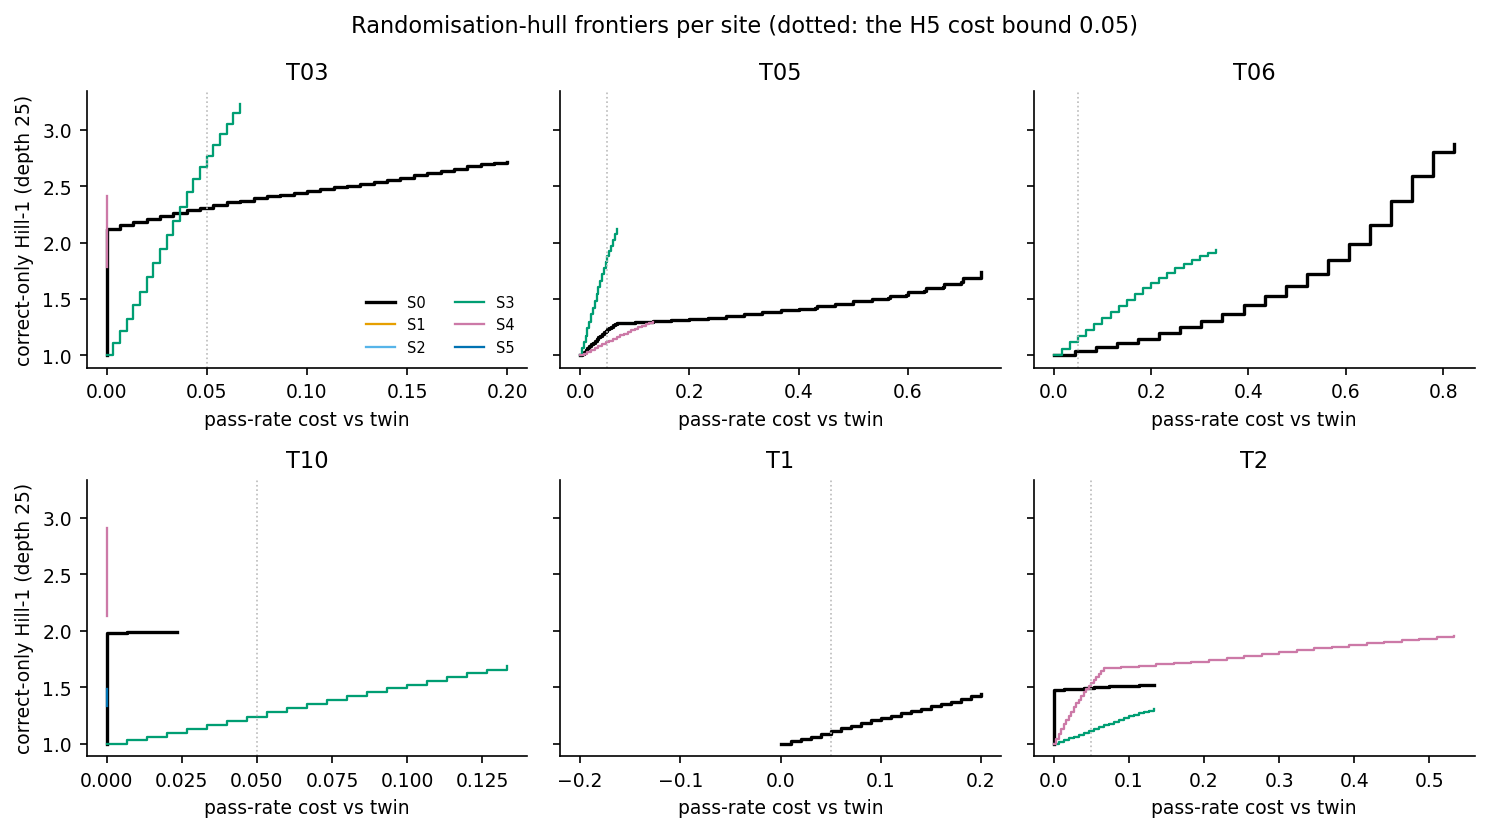

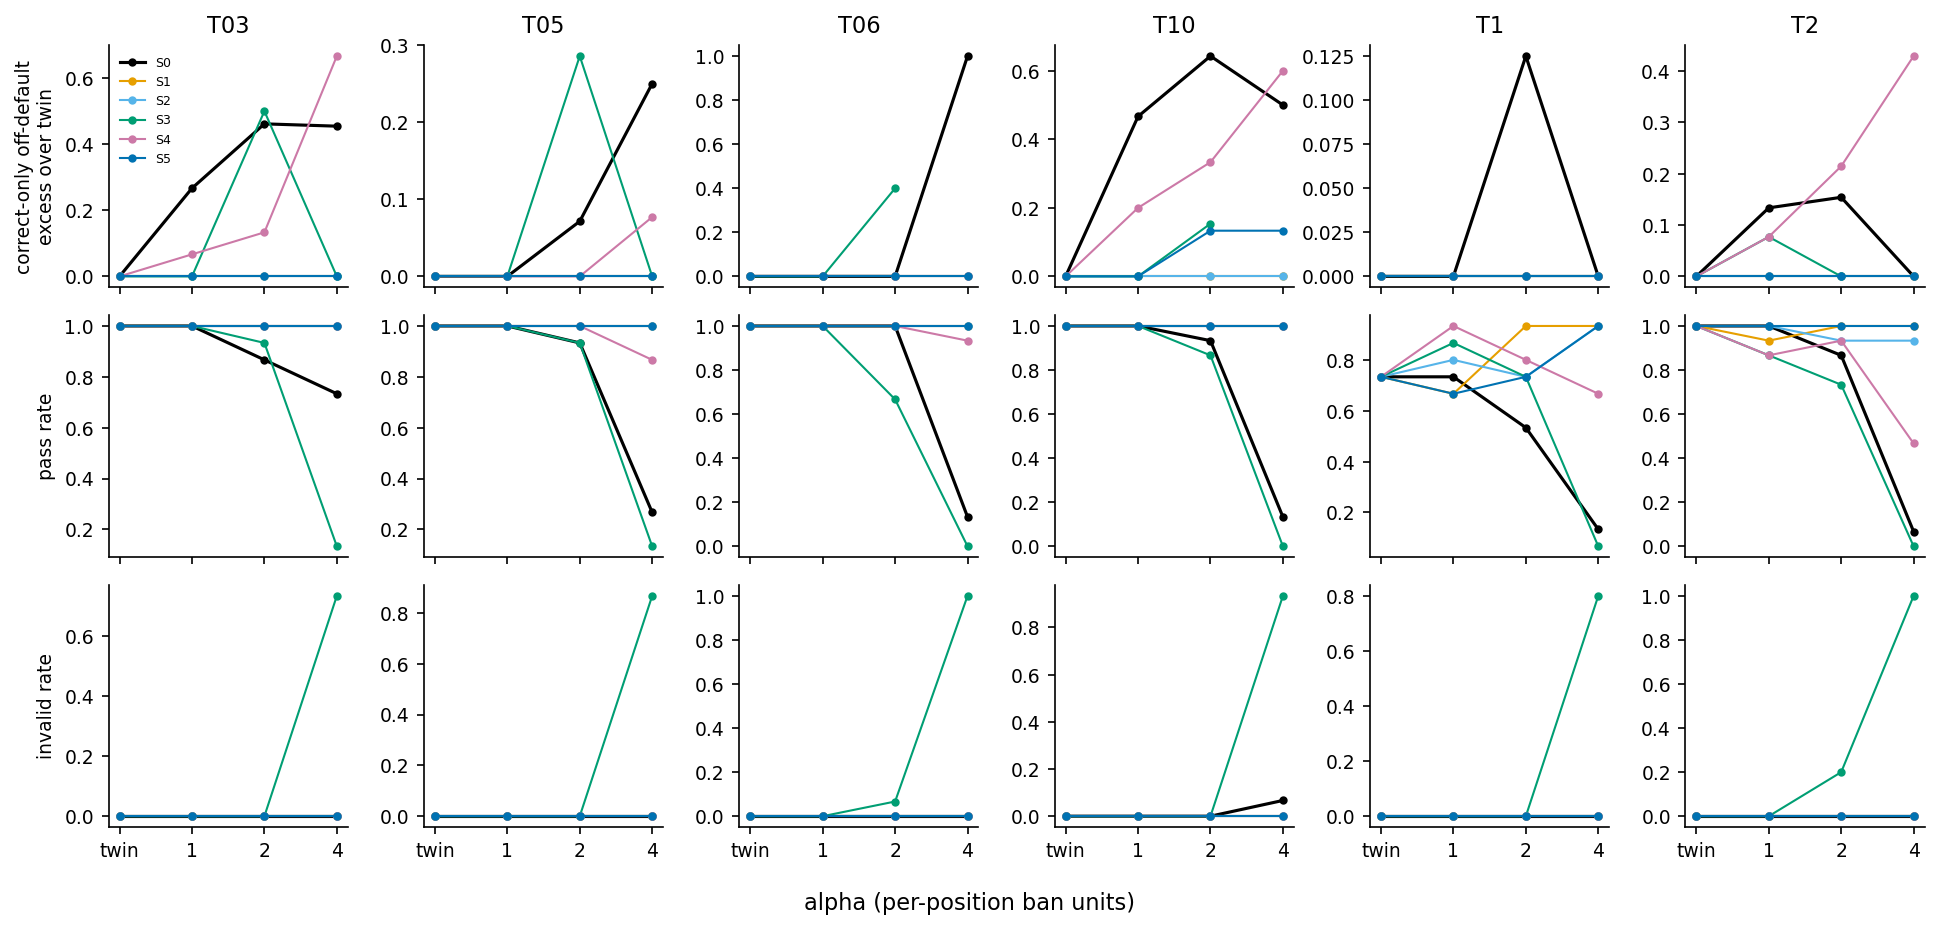

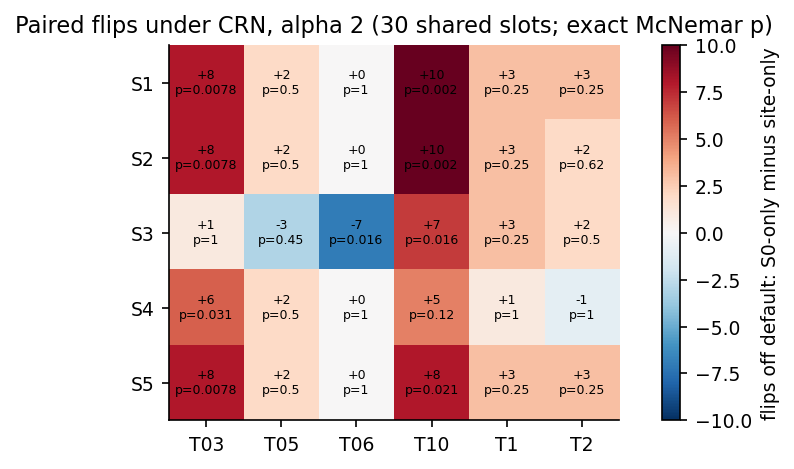

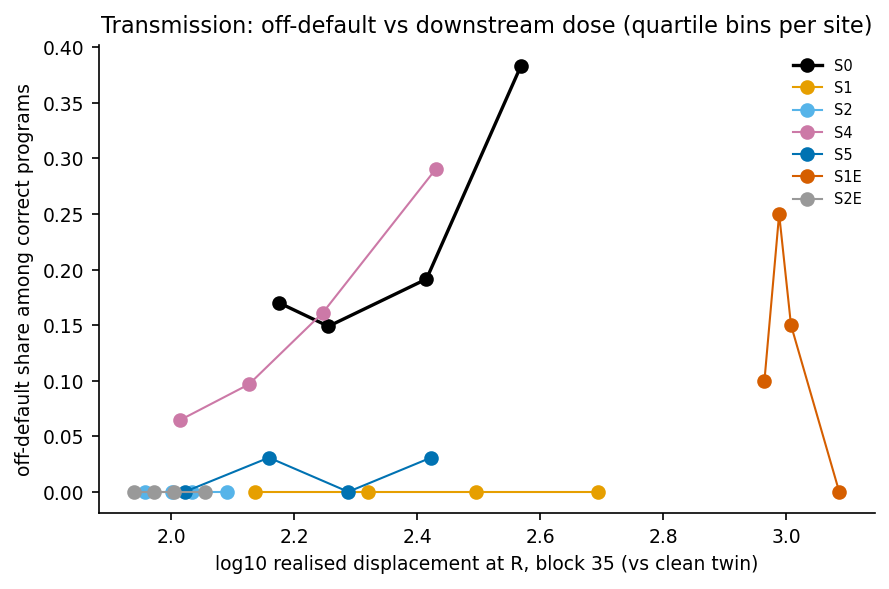

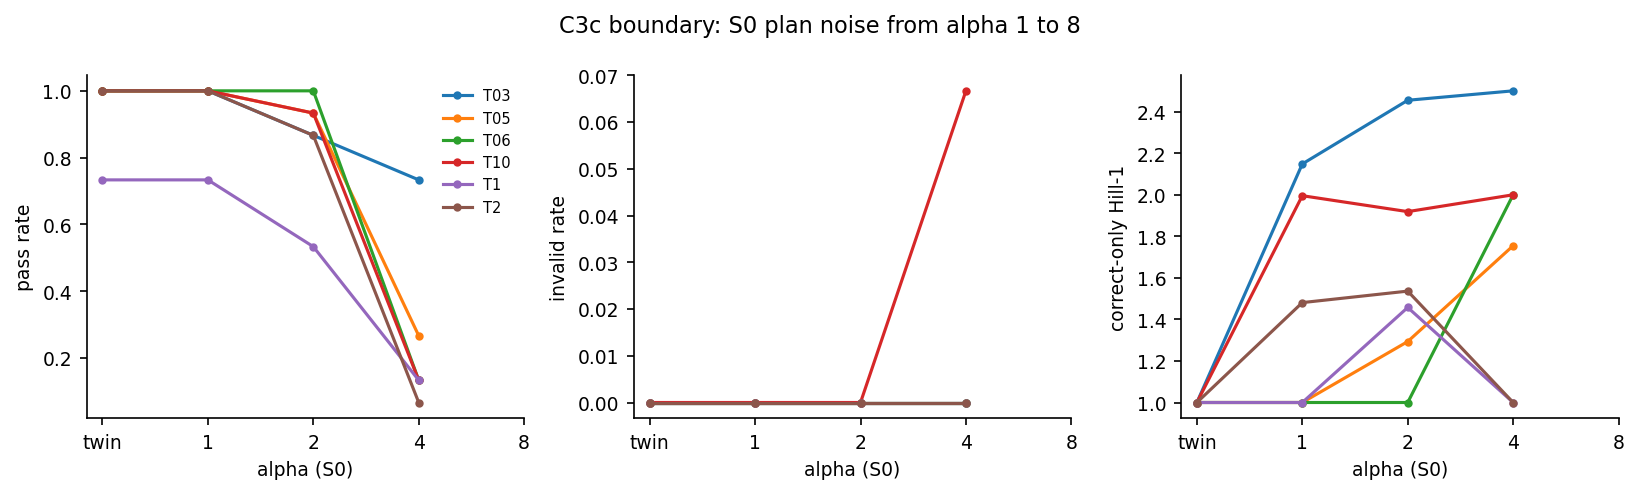

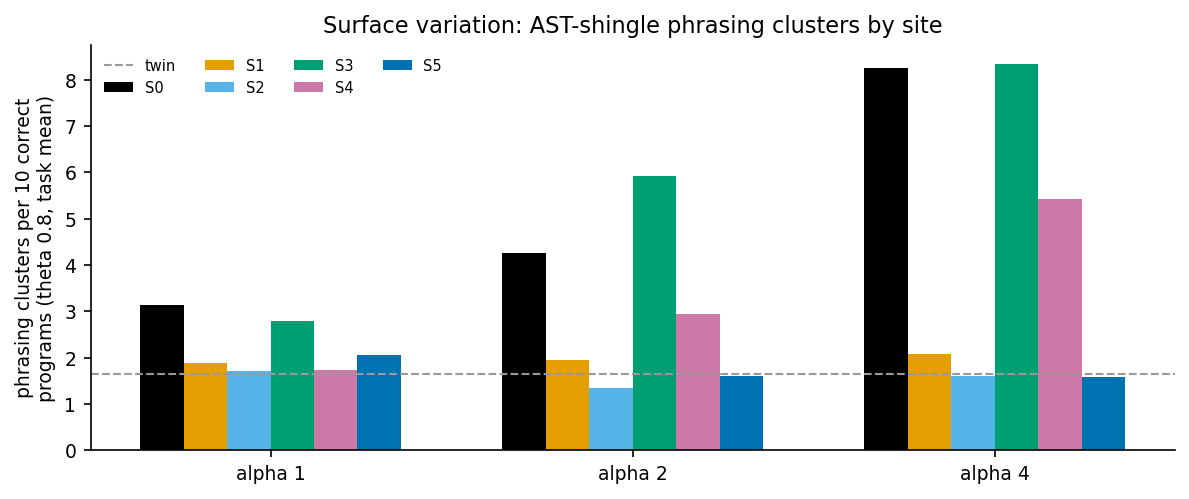

In [19]:
"""Figures (PDF + PNG, matplotlib, Type-42 fonts, colour-blind-safe Okabe-Ito palette), drawn only from results/*.json:
fig1 hull frontiers per task; fig2 dose-response; fig3 paired-flip matrix; fig4 transmission; fig5 boundary;
fig6 plan-site MDS (C3d); fig7 phrasing clusters per idea by site."""

# notebook: matplotlib.use("Agg") removed so the figures render inline; the cfg names come from the cells above

plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})
COL = {"S0": "#000000", "S1": "#E69F00", "S2": "#56B4E9", "S3": "#009E73", "S4": "#CC79A7", "S5": "#0072B2",
       "S1E": "#D55E00", "S2E": "#999999", "TOP5": "#D55E00", "TWIN": "#999999"}
SITE_NAME = {"S0": "S0 task spec, blocks 12-23", "S1": "S1 read position R", "S2": "S2 condition span",
             "S3": "S3 generated tokens 1-32", "S4": "S4 task spec, blocks 0-11", "S5": "S5 task spec, blocks 24-35"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=200)
    plt.show()  # notebook: display inline (original: plt.close(fig))


def fig1() -> None:
    h = read_json(RESULTS_DIR / "hull.json")["point"]
    fig, axs = plt.subplots(2, 3, figsize=(10, 5.6), sharey=True)
    for ax, t in zip(axs.ravel(), TASKS):
        for s in SITES:
            fr = h.get(f"{t}|{s}", {}).get("frontier")
            if fr:
                x, y = zip(*fr)
                ax.step(x, y, where="post", color=COL[s], lw=1.6 if s == "S0" else 1.1, label=s)
        ax.axvline(0.05, color="#bbbbbb", ls=":", lw=0.8)
        ax.set_title(t)
        ax.set_xlabel("pass-rate cost vs twin")
    axs[0, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axs[1, 0].set_ylabel("correct-only Hill-1 (depth 25)")
    axs[0, 0].legend(frameon=False, fontsize=7, ncol=2)
    fig.suptitle("Randomisation-hull frontiers per site (dotted: the H5 cost bound 0.05)")
    fig.tight_layout()
    save(fig, "fig1_hull_frontiers")


def fig2() -> None:
    c = read_json(RESULTS_DIR / "cells.json")
    fig, axs = plt.subplots(3, 6, figsize=(13, 6.2), sharex=True)
    for j, t in enumerate(TASKS):
        tw = c.get(f"{t}|TWIN|0", {})
        for s in SITES:
            xs, ex, pr, iv = [0], [0.0], [tw.get("pass_rate")], [tw.get("invalid_rate")]
            for a in (1, 2, 4):
                cc = c.get(f"{t}|{s}|{a}")
                if cc:
                    xs.append(a)
                    ex.append(cc.get("excess_correct_off") if cc.get("excess_correct_off") is not None else np.nan)
                    pr.append(cc.get("pass_rate"))
                    iv.append(cc.get("invalid_rate"))
            xx = [0.5 if x == 0 else x for x in xs]
            for i, v in enumerate((ex, pr, iv)):
                axs[i, j].plot(xx, v, marker="o", ms=3, color=COL[s], lw=1.5 if s == "S0" else 1, label=s)
        axs[0, j].set_title(t)
        for i in range(3):
            axs[i, j].set_xscale("log", base=2)
            axs[i, j].set_xticks([0.5, 1, 2, 4])
            axs[i, j].set_xticklabels(["twin", "1", "2", "4"])
    axs[0, 0].set_ylabel("correct-only off-default\nexcess over twin")
    axs[1, 0].set_ylabel("pass rate")
    axs[2, 0].set_ylabel("invalid rate")
    axs[0, 0].legend(frameon=False, fontsize=6)
    fig.supxlabel("alpha (per-position ban units)")
    fig.tight_layout()
    save(fig, "fig2_dose_response")


def fig3() -> None:
    pf = read_json(RESULTS_DIR / "paired_flips.json")
    for a in (1, 2, 4):
        M = np.full((len(SITES) - 1, len(TASKS)), np.nan)
        P = np.full_like(M, np.nan)
        for i, s in enumerate(SITES[1:]):
            for j, t in enumerate(TASKS):
                r = pf.get(f"{t}|{s}|{a}")
                if r:
                    tb = r["table_attempts[both,S0only,siteonly,neither]"]
                    M[i, j] = tb[1] - tb[2]
                    P[i, j] = r["mcnemar_p_attempts"]
        if a == 2:
            fig, ax = plt.subplots(figsize=(6, 3.2))
            lim = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
            im = ax.imshow(M, cmap="RdBu_r", vmin=-lim, vmax=lim)
            for i in range(M.shape[0]):
                for j in range(M.shape[1]):
                    if np.isfinite(M[i, j]):
                        ax.text(j, i, f"{int(M[i, j]):+d}\np={P[i, j]:.2g}", ha="center", va="center", fontsize=6)
            ax.set_xticks(range(len(TASKS)), TASKS)
            ax.set_yticks(range(len(SITES) - 1), SITES[1:])
            fig.colorbar(im, ax=ax, label="flips off default: S0-only minus site-only")
            ax.set_title("Paired flips under CRN, alpha 2 (30 shared slots; exact McNemar p)")
            fig.tight_layout()
            save(fig, "fig3_paired_flips")


def fig4() -> None:
    # notebook: load_rows() is the function defined above (original: from analysis import load_rows)
    rows = [r for r in load_rows() if r.get("disp35") and r["correct"] and r["k"] < 6 and
            r["site"] in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E")]
    fig, ax = plt.subplots(figsize=(6, 4))
    for s in ("S0", "S1", "S2", "S4", "S5", "S1E", "S2E"):
        rs = [r for r in rows if r["site"] == s]
        if not rs:
            continue
        x = np.log10([r["disp35"] for r in rs])
        y = np.array([float(r["off"]) for r in rs])
        bins = np.quantile(x, np.linspace(0, 1, 5))
        mx, my = [], []
        for i in range(4):
            m = (x >= bins[i]) & (x <= bins[i + 1])
            if m.sum():
                mx.append(x[m].mean())
                my.append(y[m].mean())
        ax.plot(mx, my, marker="o", color=COL[s], label=s, lw=1.6 if s == "S0" else 1)
    ax.set_xlabel("log10 realised displacement at R, block 35 (vs clean twin)")
    ax.set_ylabel("off-default share among correct programs")
    ax.set_title("Transmission: off-default vs downstream dose (quartile bins per site)")
    ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    save(fig, "fig4_transmission")


def fig5() -> None:
    b = read_json(RESULTS_DIR / "boundary.json")["per_task"]
    fig, axs = plt.subplots(1, 3, figsize=(11, 3.3))
    for t in TASKS:
        cv = b.get(t, {}).get("curve", [])
        xs = [0.5 if x["alpha"] == 0 else x["alpha"] for x in cv]
        axs[0].plot(xs, [x["pass"] for x in cv], marker="o", ms=3, label=t)
        axs[1].plot(xs, [x["invalid"] for x in cv], marker="o", ms=3, label=t)
        axs[2].plot(xs, [x["hill_correct"] if x["hill_correct"] is not None else np.nan for x in cv], marker="o",
                    ms=3, label=t)
    for ax, yl in zip(axs, ("pass rate", "invalid rate", "correct-only Hill-1")):
        ax.set_xscale("log", base=2)
        ax.set_xticks([0.5, 1, 2, 4, 8])
        ax.set_xticklabels(["twin", "1", "2", "4", "8"])
        ax.set_xlabel("alpha (S0)")
        ax.set_ylabel(yl)
    axs[0].legend(frameon=False, fontsize=7)
    fig.suptitle("C3c boundary: S0 plan noise from alpha 1 to 8")
    fig.tight_layout()
    save(fig, "fig5_boundary")


def fig7() -> None:
    c = read_json(RESULTS_DIR / "cells.json")
    fig, ax = plt.subplots(figsize=(8, 3.4))
    width = 0.12
    for i, s in enumerate(SITES):
        vals = []
        for a in (1, 2, 4):
            v = [c.get(f"{t}|{s}|{a}", {}).get("phrasing", {}).get("0.8", {}).get("clusters_per_10_programs")
                 for t in TASKS]
            v = [x for x in v if x is not None]
            vals.append(np.mean(v) if v else np.nan)
        ax.bar(np.arange(3) + (i - 2.5) * width, vals, width, color=COL[s], label=s)
    tw = [c.get(f"{t}|TWIN|0", {}).get("phrasing", {}).get("0.8", {}).get("clusters_per_10_programs") for t in TASKS]
    tw = [x for x in tw if x is not None]
    if tw:
        ax.axhline(np.mean(tw), color="#999999", ls="--", lw=1, label="twin")
    ax.set_xticks(range(3), ["alpha 1", "alpha 2", "alpha 4"])
    ax.set_ylabel("phrasing clusters per 10 correct\nprograms (theta 0.8, task mean)")
    ax.legend(frameon=False, fontsize=7, ncol=4)
    ax.set_title("Surface variation: AST-shingle phrasing clusters by site")
    fig.tight_layout()
    save(fig, "fig7_phrasing_clusters")


def main() -> None:
    for f in (fig1, fig2, fig3, fig4, fig5, fig7):  # notebook: fig6 (C3d plan-site MDS) needs the C3d results
        try:
            f()
        except Exception as e:  # noqa: BLE001 - one broken figure must not stop the others
            print(f"{f.__name__} failed: {e}")


main()

## Results summary: the demo subset next to the full run

`mini_demo_data.json` stores the full run's headline numbers under `metadata.full_run_reference` (k 0-5, 30 programs per cell, 2,000 bootstrap replicates). This cell puts them next to the demo's:

1. H5 per task and site, the best site under the frozen rule, and P(S0 argmax);
2. per site, how many correct programs at alpha 1-4 are **not** the task's default algorithm. This is the headline "S1 and S2 never change the algorithm";
3. the failure mode per site.

A final plot compares each site's H5 with the full run's.

C1-site, demo subset (15 programs per cell, B = 200): PARTIAL; S0 best on 1 of 6 tasks (raw p = 0.665)
C1-site, full run (30 programs per cell, B = 2000): PARTIAL; S0 best on 3 of 6 tasks (raw p = 0.062)

1. H5 = best correct-only Hill-1 within 0.05 pass-rate cost of the twin (1.00 = only the default algorithm)


,S0,S1,S2,S3,S4,S5,best (demo),best (full run),P(S0 argmax) demo,P(S0 argmax) full run
T03,2.31,1.0,1.0,2.77,2.41,1.00,S3,S0,0.195,0.5910
T05,1.23,1.0,1.0,1.88,1.11,1.00,S3,S3,0.070,0.3840
T06,1.04,1.0,1.0,1.17,1.00,1.00,S3,S3,0.000,0.3080
T10,1.99,1.0,1.0,1.24,2.91,1.48,S4,S4,0.000,0.3295
T1,1.11,1.0,1.0,1.00,1.00,1.00,S0,S0,0.680,0.6705
T2,1.49,1.0,1.0,1.11,1.54,1.00,S4,S0,0.550,0.9725


2. correct off-default programs / correct programs, alpha 1-4, all six tasks


,demo,full run
S0,41 / 185,81 / 379
S1,0 / 262,0 / 526
S2,0 / 260,0 / 527
S3,18 / 164,41 / 320
S4,38 / 247,54 / 484
S5,4 / 260,6 / 521


3. failure mode per site (number of tasks)


,demo,full run
S0,moves: 2; moves with cost: 3; breakage first: 1,moves: 3; moves with cost: 3
S1,no movement: 6,no movement: 6
S2,no movement: 6,no movement: 6
S3,moves: 2; moves with cost: 1; breakage first: 3,moves: 3; moves with cost: 1; breakage first: 2
S4,moves: 3; no movement: 3,moves: 2; unclassified (weak movement: 0.10 <=...
S5,no movement: 5; unclassified (weak movement: 0...,no movement: 5; unclassified (weak movement: 0...


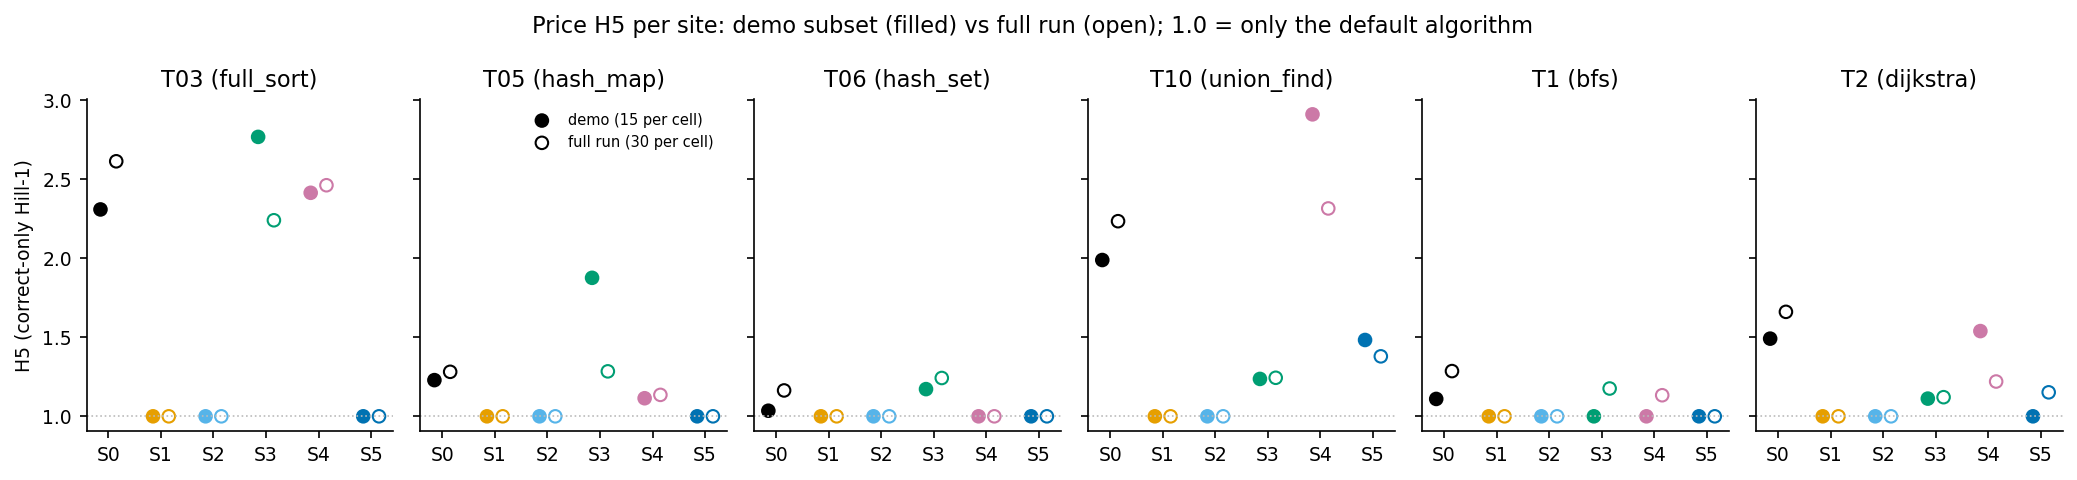

In [20]:
ref = data["metadata"]["full_run_reference"]
ref_c1 = ref["c1_site"]
n_cell = len(DEMO_K) * len(TEMPLATE_IDS)
print(f"C1-site, demo subset ({n_cell} programs per cell, B = {B}): {c1['verdict']}; S0 best on "
      f"{c1['count_S0_best']} of {c1['n_tasks']} tasks (raw p = {c1['raw_p_binom']:.3f})")
print(f"C1-site, full run (30 programs per cell, B = 2000): {ref_c1['verdict']}; S0 best on "
      f"{ref_c1['count_S0_best']} of 6 tasks (raw p = {ref_c1['raw_p_binom']:.3f})")

# 1. price H5 per task and site, best site and P(S0 argmax): demo vs full run
summary = pd.DataFrame({t: c1["per_task"][t]["H5"] for t in c1["per_task"]}).T[list(SITES)].round(2)
summary["best (demo)"] = pd.Series(c1["best_site"])
summary["best (full run)"] = pd.Series(ref_c1["best_site"])
summary["P(S0 argmax) demo"] = pd.Series({t: c1["per_task"][t].get("P_S0_argmax_boot") for t in c1["per_task"]})
summary["P(S0 argmax) full run"] = pd.Series({t: v["P_S0_argmax_boot"] for t, v in ref_c1["per_task"].items()})
print("\n1. H5 = best correct-only Hill-1 within 0.05 pass-rate cost of the twin (1.00 = only the default algorithm)")
display(summary)

# 2. correct programs that are not the task's default algorithm, per site (all tasks, alpha 1-4)
demo_off = {s: [sum(1 for r in rows if r["site"] == s and r["alpha"] in GRID_ALPHAS and r["correct"] and r["off"]),
                sum(1 for r in rows if r["site"] == s and r["alpha"] in GRID_ALPHAS and r["correct"])] for s in SITES}
ref_off = ref["correct_off_default_alpha1to4"]["counts"]
print("2. correct off-default programs / correct programs, alpha 1-4, all six tasks")
display(pd.DataFrame({"demo": {s: f"{a} / {b}" for s, (a, b) in demo_off.items()},
                      "full run": {s: f"{a} / {b}" for s, (a, b) in ref_off.items()}}))

# 3. failure mode per site (number of tasks in each mode)
ref_fm = ref["failure_modes_summary_by_site"]
print("3. failure mode per site (number of tasks)")
display(pd.DataFrame({"demo": {s: "; ".join(f"{k}: {v}" for k, v in fmodes["summary_by_site"][s].items()) for s in SITES},
                      "full run": {s: "; ".join(f"{k}: {v}" for k, v in ref_fm[s].items()) for s in SITES}}))

# 4. plot: H5 per site and task, demo (filled) vs full run (open)
fig, axs = plt.subplots(1, len(TASKS), figsize=(14, 3.2), sharey=True)
x = np.arange(len(SITES))
for ax, t in zip(axs, TASKS):
    ax.scatter(x - 0.15, [c1["per_task"][t]["H5"][s] for s in SITES], color=[COL[s] for s in SITES], s=36,
               label=f"demo ({n_cell} per cell)")
    ax.scatter(x + 0.15, [ref_c1["per_task"][t]["H5"][s] for s in SITES], facecolors="none",
               edgecolors=[COL[s] for s in SITES], s=36, label="full run (30 per cell)")
    ax.axhline(1.0, color="#bbbbbb", ls=":", lw=0.8)
    ax.set_xticks(x, SITES)
    ax.set_title(f"{t} ({DEFAULT[t]})")
axs[0].set_ylabel("H5 (correct-only Hill-1)")
axs[1].legend(frameon=False, fontsize=7, loc="upper right")
fig.suptitle("Price H5 per site: demo subset (filled) vs full run (open); 1.0 = only the default algorithm")
fig.tight_layout()
plt.show()

## What the demo shows

With the default configuration (`DEMO_K = [0, 1, 2]`, i.e. 15 programs per cell, and B = 200):

- **The inert sites reproduce the full run.** S1 (read position) and S2 (condition sentence) never produce a correct program with a non-default algorithm: 0 of 262 and 0 of 260 (full run: 0 of 526 and 0 of 527). S5 (late blocks) does so 4 times in 260 (full run: 6 of 521). S1 and S2 show no movement on all six tasks. Their programs are often byte-identical to the clean twin's (see the paired-flip table).
- **S0's effect is not just downstream dose.** At matched realised displacement at R, the transmission S0 indicator is +1.94 logit [1.44, 2.43] (full run: +2.15 [1.79, 2.51]).
- **The ranking among the live sites is a close call.** The frozen C1-site verdict is PARTIAL again, but S0 has the best H5 on only 1 of 6 tasks here (T1), against 3 of 6 in the full run (T03, T1, T2). S3 and S4 take the other five. The full run's bootstrap already flagged every per-task margin as a close call (P(S0 argmax) 0.31-0.97), and halving N moves them.
- **Moving the algorithm has a price.** S3 (generated tokens) breaks programs first: at alpha 4 most of its programs are invalid (figure 2, bottom row). Surface variation rises with alpha at S0, S3 and S4 (figure 7), while S1, S2 and S5 stay near the twin's level.

The artifact's reading of the full run is the same:

- the algorithm is chosen in the task-specification states at early-to-middle blocks;
- the read-out, condition and late-block sites are inert;
- blocks 12-23 specifically are not supported over blocks 0-11.

This is a site-specific perturbation result, for one model (Qwen3-8B in FP8) on six memorised tasks. It is not evidence of a plan representation.